# Team 19 - Overhead-Conductor Data Pipeline

**Single-notebook interface for the SA Power Networks release handover**

The notebook orchestrates independently testable Python modules in `src/`. It **does not reimplement** ingestion, validation, cleaning, imputation or evaluation: every cell below calls the same stage functions as the `oc-pipeline` command line (`src.pipeline.run_*`), so a run from this notebook and a run from the terminal produce the same files.

Sections: 0 configuration · 1 ingestion · 2 validation · 3 exploratory analysis · 4 preprocessing and deterministic recovery · 5 imputation method · 6 postprocessing and provenance · 7 evaluation and diagnostics · 8 export and report.

> Every file under `data/overhead_conductors/` is **synthetic**; no SA Power Networks operational data is read, written or quoted here. Results on synthetic data demonstrate that the pipeline runs end to end and show how the methods behave on a generated population; they do **not** establish performance on real SAPN records. Domain rules that need a SAPN decision (for example the `code_mappings` cleaning family) are shipped **unapproved** and skipped until a domain owner approves them.

## ⚙️ Project Configuration and Dataset Selection

This section defines the configuration, dataset, and output paths for the **Overhead Conductor Data Quality and Imputation Pipeline**, developed as part of the University of Adelaide Capstone Project in collaboration with SA Power Networks.

All paths are managed centrally to simplify dataset selection, configuration changes, and experimental execution.

### 0.1 Asset Class

**Selected Asset:** `overhead_conductors`

The pipeline processes synthetic overhead-conductor asset records using asset-specific schemas, cleaning rules, and imputation configurations.

### 0.2 Dataset Selection

**Selected Scenario:** `synthetic_masked`

The experiment uses two input datasets:

| Dataset | Filename | Purpose |
|---------|----------|---------|
| Measured Data | `conductors_synthetic_masked.csv` | Contains missing values that require imputation |
| Ground Truth | `conductors_synthetic_complete.csv` | Contains the corresponding complete reference values for evaluation |

The ground-truth dataset is used exclusively for evaluating imputation performance and is not provided to the imputation model during training.

### 0.3 Asset Configuration

The following configuration files are loaded from `config/overhead_conductors/`:

| Configuration File | Responsibility |
|-------------------|----------------|
| `data_schema.yaml` | Defines attributes, data types, categorical values, constraints, and predictor roles |
| `cleaning_rules.yaml` | Specifies data cleaning, standardisation, and validation rules |
| `imputation.yaml` | Defines imputation attributes, method parameters, and model configurations |
| `pipeline.yaml` | Controls pipeline execution, validation, and evaluation settings |

### 0.4 Imputation Attributes

The overhead-conductor dataset contains seven model attributes:

**Numerical Attributes**
- `installation_year`
- `distance_to_sea_km`

**Categorical Attributes**
- `voltage_category`
- `location_group`
- `corrosion_zone`
- `material`
- `covering`

These attributes are used for missing-value imputation according to the selected method and asset configuration.

### 0.5 Experimental Output

The pipeline saves results in a scenario-specific directory:

`outputs/overhead_conductors/synthetic_masked/`

Generated outputs include:

- Data quality and profiling results
- Cleaned and preprocessed datasets
- Imputed datasets
- Imputation diagnostics and provenance
- Validation results
- Ground-truth evaluation metrics
- Visualisations and HTML reports

Keeping outputs separate for each scenario supports reproducibility and comparison between imputation methods.

### 0.6 Execution Instructions

Before executing the notebook:

1. Verify that `ASSET` is set to `overhead_conductors`.
2. Select the appropriate measured and ground-truth datasets.
3. Confirm that the configuration files exist.
4. Review the output directory.
5. Run the configuration cell before executing the remaining pipeline stages.

> **Important:** Changes to datasets, configuration paths, or output locations should be made in the Project Configuration cell below. The remaining notebook cells use these settings automatically.

> **Research Note:** The included dataset is synthetic. Imputation performance on synthetic data does not establish performance on real SA Power Networks asset records.

In [ ]:
# ============================================================
# PROJECT CONFIGURATION
# ============================================================

from pathlib import Path
import os

# Automatically locate the project root
CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path for path in (CURRENT_DIR, *CURRENT_DIR.parents)
        if (path / "src" / "__init__.py").is_file()
        and (path / "config").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate the pipeline project root.")


# ---------------- ASSET CONFIGURATION ----------------

ASSET = "overhead_conductors"

CONFIG_DIR = PROJECT_ROOT / "config" / ASSET

PIPELINE_CONFIG = CONFIG_DIR / "pipeline.yaml"
DATA_SCHEMA_CONFIG = CONFIG_DIR / "data_schema.yaml"
CLEANING_CONFIG = CONFIG_DIR / "cleaning_rules.yaml"
IMPUTATION_CONFIG = CONFIG_DIR / "imputation.yaml"


# ---------------- DATASET CONFIGURATION ----------------

INPUT_FILE = "data/overhead_conductors/conductors_synthetic_masked.csv"

TRUTH_FILE = "data/overhead_conductors/conductors_synthetic_complete.csv"


# ---------------- OUTPUT CONFIGURATION ----------------

OUTPUT_DIR = "outputs/overhead_conductors/run_01"

# ---------------- DISPLAY CONFIGURATION ----------------

HOME_DIR = str(Path.home())

print("Project Root:", str(PROJECT_ROOT).replace(HOME_DIR, "~", 1))
print("Asset:", ASSET)
print("Pipeline Config:", str(PIPELINE_CONFIG).replace(HOME_DIR, "~", 1))
print("Data Schema:", str(DATA_SCHEMA_CONFIG).replace(HOME_DIR, "~", 1))
print("Cleaning Rules:", str(CLEANING_CONFIG).replace(HOME_DIR, "~", 1))
print("Imputation Config:", str(IMPUTATION_CONFIG).replace(HOME_DIR, "~", 1))
print("Measured Data:", str(INPUT_FILE).replace(HOME_DIR, "~", 1))
print("Ground Truth:", str(TRUTH_FILE).replace(HOME_DIR, "~", 1))
print("Output Directory:", str(OUTPUT_DIR).replace(HOME_DIR, "~", 1))

Project Root: ~/Desktop/GitHub/team19-asset-data/pipeline
Asset: overhead_conductors
Pipeline Config: ~/Desktop/GitHub/team19-asset-data/pipeline/config/overhead_conductors/pipeline.yaml
Data Schema: ~/Desktop/GitHub/team19-asset-data/pipeline/config/overhead_conductors/data_schema.yaml
Cleaning Rules: ~/Desktop/GitHub/team19-asset-data/pipeline/config/overhead_conductors/cleaning_rules.yaml
Imputation Config: ~/Desktop/GitHub/team19-asset-data/pipeline/config/overhead_conductors/imputation.yaml
Measured Data: ~/Desktop/GitHub/team19-asset-data/pipeline/data/overhead_conductors/conductors_synthetic_masked.csv
Ground Truth: ~/Desktop/GitHub/team19-asset-data/pipeline/data/overhead_conductors/conductors_synthetic_complete.csv
Output Directory: ~/Desktop/GitHub/team19-asset-data/pipeline/outputs/overhead_conductors/synthetic_masked


## 0. Environment Initialization

This section initializes the Python environment and imports the required libraries and reusable pipeline modules.

The notebook uses the project paths and asset configuration defined in **Section 0: Project Configuration**.

### Environment Requirements

- **Python environment:** `pipeline/.pipeline`
- **Source code:** `pipeline/src/`
- **Notebooks:** `pipeline/notebook/`
- **Configuration:** Selected through the Project Configuration cell.

The project root is detected automatically, allowing the notebook to run from the `pipeline/` directory, the `notebook/` directory, or the parent repository directory.

> **Note:** Run the Project Configuration cell before executing this section. Any changes to asset classes, datasets, configuration files, or output directories should be made in Section 0.

In [7]:
# ============================================================
# ENVIRONMENT INITIALIZATION
# ============================================================

import json
import os
import shutil
import sys

import pandas as pd
from IPython.display import display

# Make project modules importable
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import __version__

from src.notebook import (
    display_path,
    key_values,
    list_outputs,
    missingness_before_after,
    notebook_paths,
    show_figures,
    show_images,
    table,
)

# Display environment information
HOME_DIR = str(Path.home())

print("Pipeline root:", str(PROJECT_ROOT).replace(HOME_DIR, "~", 1))
print("Python executable:", str(sys.executable).replace(HOME_DIR, "~", 1))
print("Pipeline version:", __version__)

Pipeline root: ~/Desktop/GitHub/team19-asset-data/pipeline
Python executable: ~/Desktop/GitHub/team19-asset-data/pipeline/.pipeline/bin/python
Pipeline version: 1.1.0


Change the paths below when moving from the synthetic sample to approved partner data. The notebook distinguishes four things that are easy to conflate:

| Name | What it is | Default |
|---|---|---|
| `INPUT_CSV` | the records to complete (operational run, sections 1-6) | synthetic sample with injected data-quality defects |
| `TRUTH_CSV` | a **complete reference** with every model attribute known (evaluation mode, section 7) | synthetic complete reference |
| evaluation partitions | fit / validation / test, drawn by feeder inside the evaluation stage and written to `evaluation/partition_manifest.csv` | from `config/overhead_conductors/pipeline.yaml` |

Environment variables `OC_NOTEBOOK_INPUT`, `OC_NOTEBOOK_TRUTH`, `OC_NOTEBOOK_RUN_DIR` override these without editing the notebook (the automated test uses them). `OC_NOTEBOOK_OVERRIDES` may hold a JSON object of hyperparameter overrides for development runs; leave it unset for a release run so the approved `config/overhead_conductors/imputation.yaml` values apply.

In [ ]:
PATHS = notebook_paths(PROJECT_ROOT, {
    "input": INPUT_FILE,
    "truth": TRUTH_FILE,
    "run_dir": OUTPUT_DIR,
})

INPUT_CSV, TRUTH_CSV, RUN_DIR = (PATHS[k] for k in ("input", "truth", "run_dir"))

# Development-only hyperparameter overrides (recorded in run_metadata.json); {} for a release run.
OVERRIDES = json.loads(os.environ.get("OC_NOTEBOOK_OVERRIDES", "{}"))
# Set to a name (e.g. "J. Smith, SAPN") to record approval of the CURRENT configuration content from
# this notebook. None leaves config/overhead_conductors/approvals.json untouched.
APPROVE_CONFIGURATION_AS = None
# Start from an empty run directory so no file from an earlier run can be mistaken for this one.
FRESH_RUN = True

for name, path in PATHS.items():
    print(f"{name:>8}: {display_path(path, PROJECT_ROOT)}")
print("overrides:", OVERRIDES or "none")

   input: pipeline/data/overhead_conductors/conductors_synthetic_dirty.csv
   truth: pipeline/data/overhead_conductors/conductors_synthetic_complete.csv
 run_dir: pipeline/outputs/overhead_conductors/run_01
overrides: none


### Configuration check and approval state

`ConfigurationManager` parses the four YAML files (`data_schema.yaml`, `cleaning_rules.yaml`, `imputation.yaml`, `pipeline.yaml`), runs the cross-file checks (model attributes in the imputation config must match the schema; cleaning mappings must map onto allowed labels; forbidden predictors must not be model attributes) and compares each file's SHA-256 with `config/overhead_conductors/approvals.json`. In `release` mode every stage refuses to run unless all four files are valid and approved at their current content; in `development` mode the state is recorded in the run metadata and the stage continues.

In [ ]:
from src.configuration import ConfigurationManager, load_settings
from src.pipeline import RunPaths, read_metadata

settings = load_settings(PIPELINE_CONFIG)
manager = ConfigurationManager(settings)
check = manager.check()

print("Execution mode:", settings.execution_mode)
print("Configuration valid:", check.is_valid, "| all files approved:", check.all_approved, "| ready:", check.ready)
display(check.states_table())
display(check.findings_table())

Execution mode: development
Configuration valid: True | all files approved: False | ready: False


,file,status,sha256,approved_by,approved_at,note
0,data_schema.yaml,approved,6a7c9e7395ce,Team 19 (synthetic sample only),2026-11-01T00:49:55+00:00,recover_source added for asset_age -> installa...
1,cleaning_rules.yaml,approved,2058ab879803,Team 19 (synthetic sample only),2026-11-01T00:44:35+00:00,Approved for the synthetic sample data in data...
2,imputation.yaml,approved,d8e7f98eadd0,Team 19 (synthetic sample only),2026-11-01T00:44:35+00:00,Approved for the synthetic sample data in data...
3,pipeline.yaml,changed,2e3d9f2c1004,Team 19 (synthetic sample only),2026-11-01T00:59:23+00:00,evaluation-mode settings added; synthetic samp...


,level,file,message
0,warning,cleaning_rules.yaml,rule family 'code_mappings' needs domain appro...
1,info,cleaning_rules.yaml,rule family 'sentinel_values' is approved for ...
2,info,cleaning_rules.yaml,rule family 'out_of_range' is approved for syn...
3,info,cleaning_rules.yaml,rule family 'unknown_category' is approved for...
4,info,cleaning_rules.yaml,rule family 'non_integer' is approved for synt...
5,info,imputation.yaml,selected_hyperparameters override the defaults...


In [4]:
if APPROVE_CONFIGURATION_AS:
    manager.approve_all(by=APPROVE_CONFIGURATION_AS, note="approved from pipeline.ipynb")
    check = manager.check()
    display(check.states_table())
elif not check.ready and settings.execution_mode == "release":
    print("Release mode will refuse to run. Fix the findings above, then approve the files "
          "(oc-pipeline config approve --by <name>, or set APPROVE_CONFIGURATION_AS), "
          "or switch execution.mode to development in config/overhead_conductors/pipeline.yaml.")
else:
    print("Configuration state unchanged.")

Configuration state unchanged.


### What the configuration says

Schema roles, the two **primary targets** (`installation_year`, `material`) inside the seven **model attributes**, the forbidden predictors, the cleaning rule families with their approval state, and the registered imputation methods with the hyperparameters that will be used.

In [5]:
summaries = manager.summaries(check.loaded)
display(summaries["schema_summary"])
display(summaries["schema_columns"])
display(summaries["cleaning_families"])
display(summaries["imputation_methods"])
display(summaries["imputation_columns"])

schema, rules, config = check.loaded.schema, check.loaded.cleaning_rules, check.loaded.imputation
run = RunPaths(RUN_DIR)
if FRESH_RUN and RUN_DIR.exists():
    shutil.rmtree(RUN_DIR)
RUN_DIR.mkdir(parents=True, exist_ok=True)

,setting,value
0,asset_class,overhead_conductors
1,id_column,segment_id
2,group_column,feeder_id
3,snapshot_year,2014
4,primary_targets,"installation_year, material"
5,model_attributes,"installation_year, distance_to_sea_km, voltage..."
6,forbidden_predictors,"segment_id, feeder_id, asset_age, conductor_ty..."
7,missing_tokens,"'', 'NA', 'N/A', 'NaN', 'null', 'NULL', 'None'..."
8,column_mapping,(none)


,column,role,dtype,required,allowed,min,max,sentinels,derived_from
0,segment_id,identifier,string,True,,,,,
1,feeder_id,group,string,False,,,,,
2,installation_year,target,integer,True,,1900.0,2014.0,"0, 9999",
3,distance_to_sea_km,predictor,float,True,,0.0,400.0,"-1, 9999",
4,voltage_category,predictor,category,True,"LV, 11/7.6 kV, 19 kV SWER, 33 kV, 66 kV",,,,
5,location_group,predictor,category,True,"Urban, Regional, Rural",,,,
6,corrosion_zone,predictor,category,True,"Low, Severe, Very Severe",,,,
7,material,target,category,True,"Aluminium, Copper, Steel",,,,
8,covering,predictor,category,True,"Bare, Covered",,,,
9,asset_age,derived,integer,False,,,,,installation_year


,family,requires_domain_approval,approved,approved_by,active,note
0,code_mappings,True,False,,False,Conductor-type and product codes are domain in...
1,sentinel_values,True,True,Team 19 (synthetic sample only),True,"0 and 9999 in installation_year, -1 and 9999 i..."
2,out_of_range,True,True,Team 19 (synthetic sample only),True,"Years outside [1900, snapshot_year] and distan..."
3,unknown_category,True,True,Team 19 (synthetic sample only),True,Labels outside the allowed list become missing...
4,non_integer,True,True,Team 19 (synthetic sample only),True,Fractional years are rounded to the nearest year.
5,non_numeric,False,True,,True,Text in a numeric column cannot be kept; it be...


,method,selected,reference,hyperparameters
0,median_mode,False,True,"{'numeric_strategy': 'median', 'categorical_st..."
1,missforest,False,False,"{'n_estimators': 100, 'max_iter': 20, 'random_..."
2,predictive_missforest,True,False,"{'n_estimators': 100, 'n_passes': 5, 'random_s..."


,role,columns
0,numeric,"installation_year, distance_to_sea_km"
1,categorical,"voltage_category, location_group, corrosion_zo..."
2,excluded,"segment_id, feeder_id, conductor_type, asset_a..."
3,constraints,"{'installation_year': {'data_type': 'integer',..."


## 1. Data ingestion

**Purpose:** preserve the original input, record its structure and checksum, and keep every value as the text it arrived as. This stage does *not* coerce numeric values, normalise categories, delete rows, or fill missing values.

In [6]:
from src.ingestion import ingest_csv

ingestion = ingest_csv(
    input_csv=INPUT_CSV,
    output_dir=RUN_DIR / "ingestion",
    overwrite=True,
)

raw_frame = ingestion.frame

print("Ingestion completed successfully.")
print("Records:", len(raw_frame))
print("Columns:", len(raw_frame.columns))
print("Report:", display_path(ingestion.report_json, PROJECT_ROOT))

Ingestion completed successfully.
Records: 10005
Columns: 13
Report: pipeline/outputs/overhead_conductors/run_01/ingestion/ingestion_report.json


In [7]:
display(raw_frame.head(10))

,segment_id,feeder_id,installation_year,asset_age,voltage_category,location_group,corrosion_zone,distance_to_sea_km,material,covering,length_km,data_status,record_version
0,SEG_000147,R_FDR_030,1935.0,79.0,19 kV SWER,Rural,Severe,32.08,Steel,,,Synthetic,Complete reference
1,SEG_002263,R_FDR_010,1955.0,59.0,11/7.6 kV,Rural,Low,281.14,Copper,Bare,0.3335,Synthetic,Complete reference
2,SEG_001822,U_FDR_025,1966.0,48.0,19 kV SWER,Urban,Very Severe,11.22,,,0.1246,Synthetic,Complete reference
3,SEG_000249,R_FDR_003,1992.0,22.0,19 kV SWER,Rural,Low,278.95,Steel,Bare,0.7929,Synthetic,Complete reference
4,SEG_001904,R_FDR_045,,,11/7.6 kV,Rural,Severe,31.02,Steel,Bare,6.1902,Synthetic,Complete reference
5,SEG_006358,R_FDR_002,1958.0,56.0,19 kV SWER,Rural,Severe,25.18,Steel,Bare,0.5729,Synthetic,Complete reference
6,SEG_003825,U_FDR_021,1961.0,53.0,,Urban,Severe,62.96,Steel,Bare,0.5642,Synthetic,Complete reference
7,SEG_008154,R_FDR_002,1978.0,36.0,11/7.6 kV,,Severe,,,Bare,0.2935,Synthetic,Complete reference
8,SEG_004851,R_FDR_012,1969.0,45.0,SWER,Rural,Severe,35.98,Steel,,0.4986,Synthetic,Complete reference
9,SEG_002113,U_FDR_023,1992.0,22.0,,Urban,Low,25.25,Steel,,0.1417,Synthetic,Complete reference


In [8]:
report = ingestion.report

summary = pd.DataFrame({
    "Property": [
        "Source file",
        "SHA-256",
        "Total records",
        "Total columns",
        "File size (bytes)",
        "Duplicate columns",
        "Inconsistent rows",
    ],
    "Value": [
        report["source_file"],
        report["sha256"][:16] + "...",
        report["rows"],
        report["columns"],
        report["file_size_bytes"],
        len(report["duplicate_columns"]),
        report["inconsistent_row_count"],
    ],
})

display(summary)

,Property,Value
0,Source file,conductors_synthetic_dirty.csv
1,SHA-256,bfac4063aa810fdd...
2,Total records,10005
3,Total columns,13
4,File size (bytes),979926
5,Duplicate columns,0
6,Inconsistent rows,0


## 2. Data validation

The quality stage maps the file's headers onto the schema (`column_mapping`), reports structural, identifier, numeric, categorical and derived-field issues, and writes `quality_report.csv` and a byte-for-byte `source_records.csv` into the run directory. It **does not fix** invalid values. A clean synthetic reference produces an empty findings table; the dirty sample produces warnings. With `quality.fail_on_error: true` an error-level finding (missing required column, duplicate identifiers, no observed target values) stops the run here, by design.

In [9]:
from src.pipeline import run_quality

aligned_frame, quality = run_quality(INPUT_CSV, run, settings)
quality_meta = read_metadata(run)["quality"]

print("Renamed columns:", quality_meta["renamed_columns"] or "none")
print("Unknown columns (carried through):", quality_meta["unknown_columns"] or "none")
print("Missing required columns:", quality_meta["missing_required"] or "none")
print(f"Findings: {quality.n_errors} errors, {quality.n_warnings} warnings ->", display_path(run.quality_report, PROJECT_ROOT))
display(table(quality.issues, 40))

2026-11-06 01:16:45 WARNING configuration: development run on unapproved configuration (pipeline.yaml=changed)
2026-11-06 01:16:45 INFO quality: 10005 rows, 13 columns, 0 errors, 12 warnings (0.1s)


Renamed columns: none
Unknown columns (carried through): none
Missing required columns: none
Findings: 0 errors, 12 warnings -> pipeline/outputs/overhead_conductors/run_01/quality_report.csv


,check,column,severity,count,rate,detail
0,derived_field_mismatch,asset_age,warning,30,0.002999,asset_age != 2014 - installation_year (snapshot_year in data_schema.yaml may not match...
1,exact_duplicate_row,,warning,5,0.000500,Rows identical in every column (first occurrence kept by the cleaner).
2,non_numeric_value,distance_to_sea_km,warning,3,0.000300,"'12,5' x2; 'abc' x1"
3,non_numeric_value,installation_year,warning,10,0.001000,'1956.0.0' x3; '1958.0.0' x3; '1960.0.0' x1; '1955.0.0' x1; '1966.0.0' x1; '1983.0.0' x1
4,out_of_range,installation_year,warning,14,0.001399,"Outside [1900.0, 2014.0]: 2031.0 x11; 1899.0 x3"
5,sentinel_value,distance_to_sea_km,warning,4,0.000400,9999.0 x3; -1.0 x1
6,sentinel_value,installation_year,warning,16,0.001599,9999.0 x12; 0.0 x4
7,unknown_category,corrosion_zone,warning,20,0.001999,Not in the allowed list: 'L' x17; 'very-severe' x2; 'Very Severe' x1
8,unknown_category,covering,warning,30,0.002999,Not in the allowed list: 'Uncovered' x30
9,unknown_category,location_group,warning,11,0.001099,Not in the allowed list: 'Metro' x11


## 3. Exploratory data analysis 

Schema-free profiling of the ingested text: blank and null rates per column, tokens that *may* stand for missing values (reported for review, never converted), suggested types, distributions, outliers, missing-value patterns and pairwise relationships. Nothing is written back to the data. Figures are rendered in memory; the schema-aware profile written to `profile/` comes after cleaning (section 4).

In [10]:
from src.profiling import profile_dataset, render_discovery_figures

profile = profile_dataset(raw_frame)
print({k: v for k, v in profile.summary.items() if k != "note"})
print(profile.summary["note"])
display(profile.tables["column_profile"])
display(profile.tables["potential_missing_tokens"])
display(table(profile.tables["missing_patterns"], 10))
display(table(profile.tables["relationships"], 15))

{'n_rows': 10005, 'n_columns': 13, 'duplicate_rows': 5, 'duplicate_column_names': [], 'missing_cells': 17911, 'missing_rate': 0.13770806904240188, 'numeric_columns': ['installation_year', 'asset_age', 'distance_to_sea_km', 'length_km'], 'categorical_columns': ['voltage_category', 'location_group', 'corrosion_zone', 'material', 'covering', 'data_status', 'record_version']}
Suggested types, outliers, and missing tokens require review; no input values were changed.


,position,column,suggested_type,n_rows,n_observed,n_missing,missing_rate,n_unique_observed,sample_values
0,0,segment_id,identifier,10005,10005,0,0.000000,10000,"SEG_000147, SEG_002263, SEG_001822"
1,1,feeder_id,identifier,10005,10005,0,0.000000,100,"R_FDR_030, R_FDR_010, U_FDR_025"
2,2,installation_year,numeric,10005,8029,1976,0.197501,100,"1935.0, 1955.0, 1966.0"
3,3,asset_age,numeric,10005,8004,2001,0.200000,85,"79.0, 59.0, 48.0"
4,4,voltage_category,categorical,10005,8004,2001,0.200000,12,"19 kV SWER, 11/7.6 kV, SWER"
5,5,location_group,categorical,10005,8003,2002,0.200100,7,"Rural, Urban, Regional"
6,6,corrosion_zone,categorical,10005,8004,2001,0.200000,8,"Severe, Low, Very Severe"
7,7,distance_to_sea_km,numeric,10005,8028,1977,0.197601,6293,"32.08, 281.14, 11.22"
8,8,material,categorical,10005,8029,1976,0.197501,16,"Steel, Copper, Aluminium"
9,9,covering,categorical,10005,8029,1976,0.197501,9,"Bare, Covered, unknown"


,column,token,count
0,installation_year,n/a,11
1,installation_year,na,5
2,installation_year,-,4
3,installation_year,null,4
4,installation_year,unknown,1
5,distance_to_sea_km,n/a,11
6,distance_to_sea_km,-,9
7,distance_to_sea_km,unknown,4
8,distance_to_sea_km,na,3
9,distance_to_sea_km,null,3


,pattern,missing_columns,n_rows,share
0,0000000000000,(complete),1665,0.166417
1,0000001000000,corrosion_zone [6],450,0.044978
2,0000000000100,length_km [10],448,0.044778
3,0000100000000,voltage_category [4],432,0.043178
4,0000000100000,distance_to_sea_km [7],430,0.042979
5,0000010000000,location_group [5],421,0.042079
6,0011000000000,"installation_year [2], asset_age [3]",412,0.041179
7,0000000010000,material [8],411,0.041079
8,0000000001000,covering [9],406,0.040580
9,0000000110000,"distance_to_sea_km [7], material [8]",123,0.012294


,column_a,column_b,statistic,value,n_pairwise_complete
0,installation_year,asset_age,spearman_rho,-0.993499,7994
1,installation_year,distance_to_sea_km,spearman_rho,-0.001378,6390
2,installation_year,length_km,spearman_rho,0.044558,6397
3,asset_age,distance_to_sea_km,spearman_rho,-0.000038,6398
4,asset_age,length_km,spearman_rho,-0.044221,6405
5,distance_to_sea_km,length_km,spearman_rho,0.007834,6382
6,voltage_category,location_group,cramers_v,0.217098,6399
7,voltage_category,corrosion_zone,cramers_v,0.034351,6426
8,voltage_category,material,cramers_v,0.086646,6406
9,voltage_category,covering,cramers_v,0.000000,6425


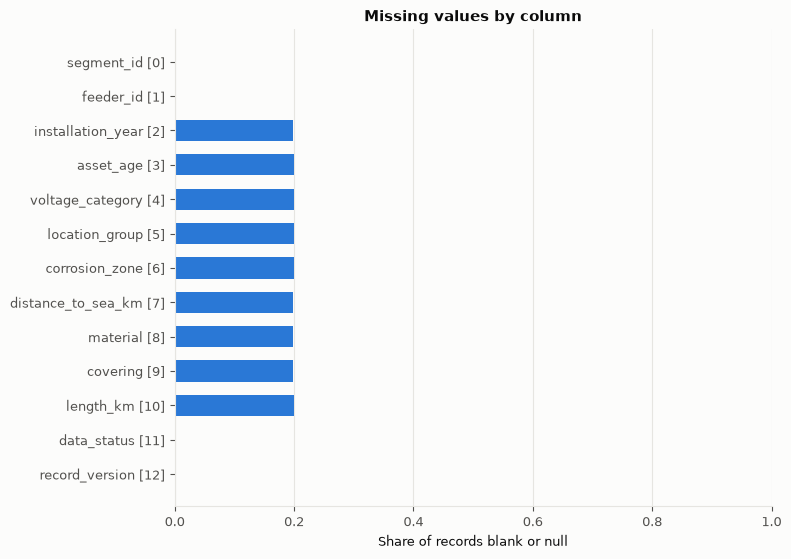

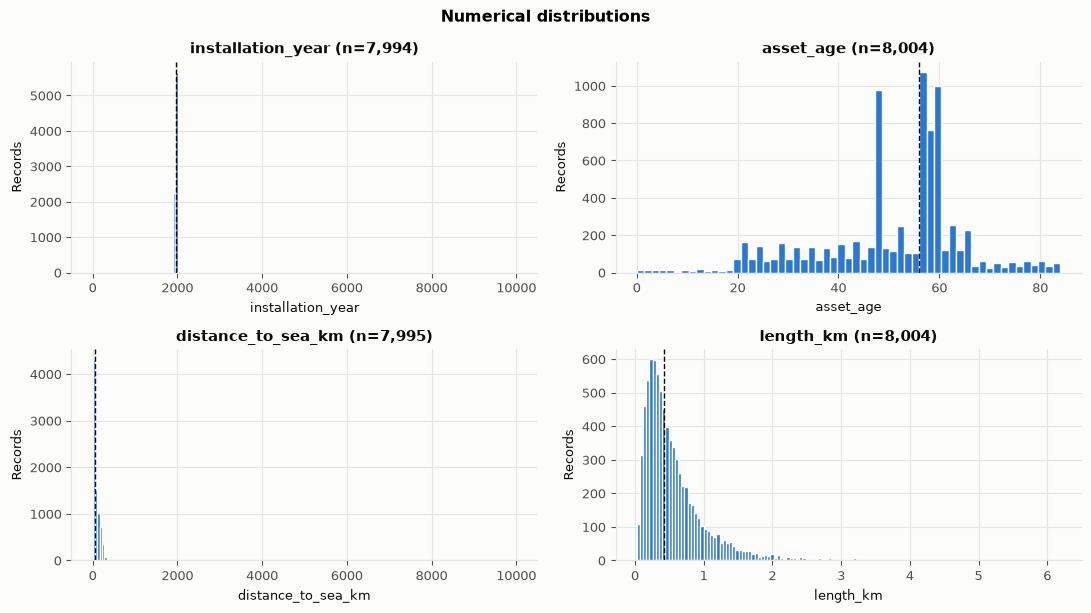

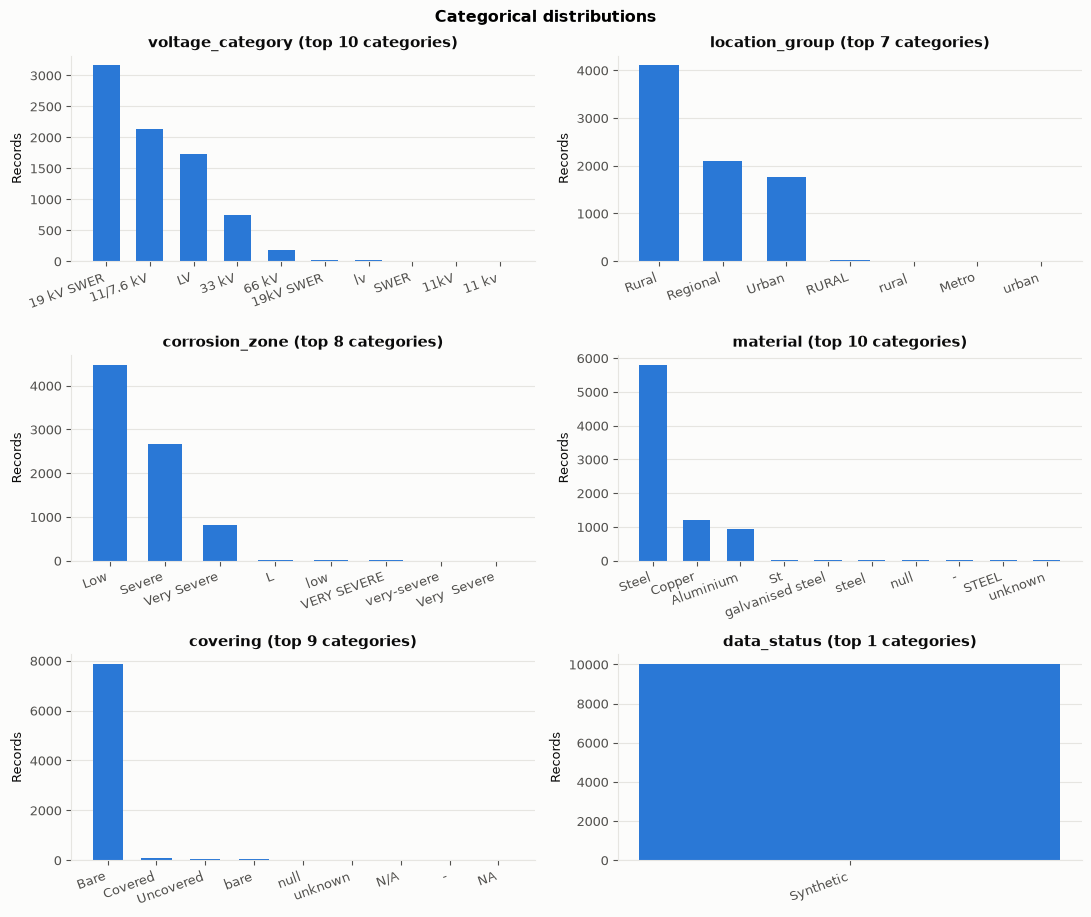

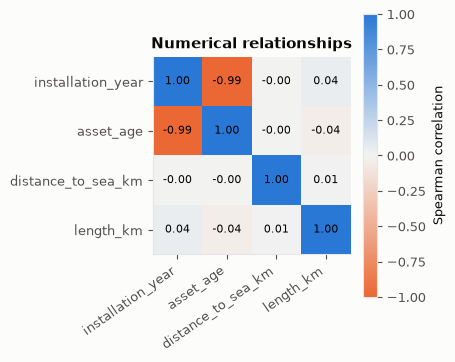

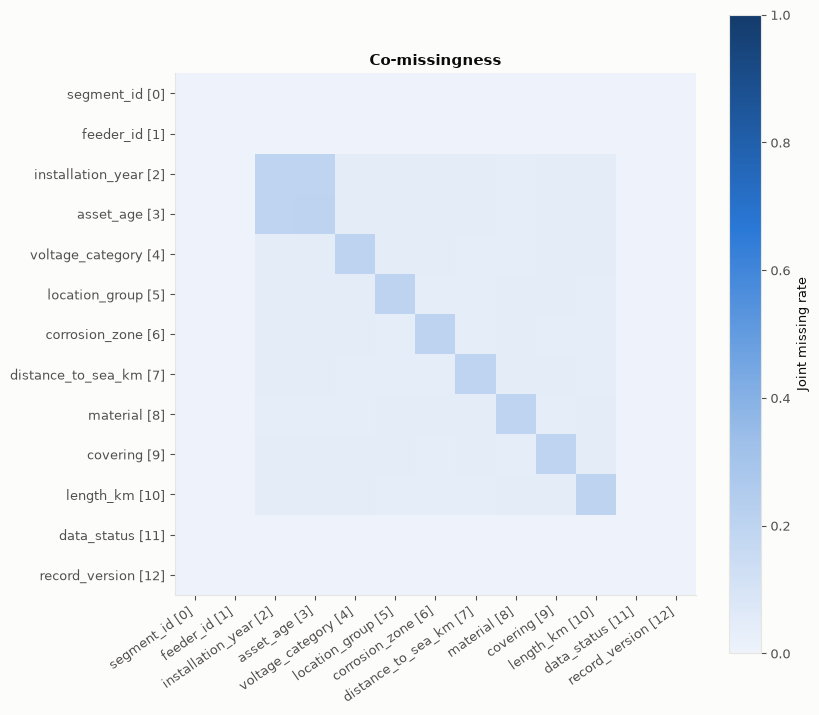

In [11]:
show_figures(render_discovery_figures(raw_frame, profile))

## 4. Preprocessing and deterministic recovery

Three steps, each audited:

1. **Cleaning** (`cleaning_rules.yaml`): documented corrections with a per-cell log. Rule families are split into *safe* normalisation (whitespace, missing tokens, label case, spelling variants of an allowed label) and *domain decisions* (code mappings such as `AAC -> Aluminium`, sentinel years, out-of-range values, unknown categories). The domain families run only when `approval.<family>.approved` is true and name who approved them; the shipped `code_mappings` are **not approved** (they need a SAPN decision) and are skipped, which the log and the report state.
2. **Schema-aware profiling** of the cleaned, typed records into `profile/`.
3. **Deterministic recovery and leakage control**: `installation_year` is restored from an observed `asset_age` (`snapshot_year - asset_age`, provenance *derived*, range-checked) before any model runs; then the model attributes are selected and the forbidden predictors are refused. `length_km` is not a model attribute and is carried through unchanged; its gaps stay **unresolved** rather than being filled by an unapproved rule.

The dry run first shows what cleaning *would* change; the following cell applies it.

In [12]:
from src.quality import plan_changes

plan = plan_changes(aligned_frame, schema, rules)
print({k: plan.summary[k] for k in ("rows_in", "rows_out", "cells_changed", "rows_dropped")})
print("Rule families skipped (domain approval pending):", plan.summary["inactive_families"] or "none")
print("Code mappings pending approval (values left as they are):", plan.summary["pending_code_mappings"] or "none")
display(plan.log.groupby(["rule", "column"]).size().reset_index(name="n_cells"))
display(table(plan.log, 15))

{'rows_in': 10005, 'rows_out': 10000, 'cells_changed': 455, 'rows_dropped': 5}
Rule families skipped (domain approval pending): ['code_mappings']
Code mappings pending approval (values left as they are): {'location_group': 11, 'material': 3}


,rule,column,n_cells
0,exact_duplicate_row,*,5
1,label_case,corrosion_zone,19
2,label_case,covering,30
3,label_case,location_group,37
4,label_case,material,19
5,label_case,voltage_category,11
6,missing_token,covering,25
7,missing_token,distance_to_sea_km,30
8,missing_token,installation_year,25
9,missing_token,material,25


,row,record_id,column,old_value,new_value,rule
0,3151,SEG_009236,*,SEG_009236,dropped,exact_duplicate_row
1,5159,SEG_006154,*,SEG_006154,dropped,exact_duplicate_row
2,6656,SEG_001942,*,SEG_001942,dropped,exact_duplicate_row
3,6834,SEG_009482,*,SEG_009482,dropped,exact_duplicate_row
4,8169,SEG_004571,*,SEG_004571,dropped,exact_duplicate_row
5,1007,SEG_001979,segment_id,SEG_001979,SEG_001979,whitespace
6,1648,SEG_000852,segment_id,SEG_000852,SEG_000852,whitespace
7,3090,SEG_007654,segment_id,SEG_007654,SEG_007654,whitespace
8,3271,SEG_006600,segment_id,SEG_006600,SEG_006600,whitespace
9,3429,SEG_009354,segment_id,SEG_009354,SEG_009354,whitespace


2026-11-06 01:16:46 WARNING configuration: development run on unapproved configuration (pipeline.yaml=changed)
2026-11-06 01:16:47 INFO cleaning: 10005 -> 10000 rows, 455 cells changed, 5 rows dropped (0.1s)
2026-11-06 01:16:47 WARNING configuration: development run on unapproved configuration (pipeline.yaml=changed)


Cleaned records: pipeline/outputs/overhead_conductors/run_01/cleaned.csv | log: pipeline/outputs/overhead_conductors/run_01/cleaning_log.csv
{'rows_in': 10005, 'rows_out': 10000, 'cells_changed': 455, 'rows_dropped': 5}


2026-11-06 01:16:48 INFO profiling: 8 tables, 9 figures (1.2s)


,column,role,dtype,n_rows,n_observed,n_missing,missing_rate
0,segment_id,identifier,string,10000,10000,0,0.0000
1,feeder_id,group,string,10000,10000,0,0.0000
2,installation_year,target,integer,10000,7960,2040,0.2040
3,distance_to_sea_km,predictor,float,10000,7988,2012,0.2012
4,voltage_category,predictor,category,10000,8000,2000,0.2000
5,location_group,predictor,category,10000,7989,2011,0.2011
6,corrosion_zone,predictor,category,10000,8000,2000,0.2000
7,material,target,category,10000,7997,2003,0.2003
8,covering,predictor,category,10000,8000,2000,0.2000
9,asset_age,derived,integer,10000,8000,2000,0.2000


,pattern,missing_columns,n_missing_columns,n_rows,share
0,0000000,(complete),0,2071,0.2071
1,0000100,corrosion_zone,1,533,0.0533
2,0100000,distance_to_sea_km,1,531,0.0531
3,1000000,installation_year,1,522,0.0522
4,0010000,voltage_category,1,519,0.0519
5,0001000,location_group,1,519,0.0519
6,0000010,material,1,518,0.0518
7,0000001,covering,1,514,0.0514
8,0100010,"distance_to_sea_km, material",2,150,0.0150
9,0001010,"location_group, material",2,143,0.0143


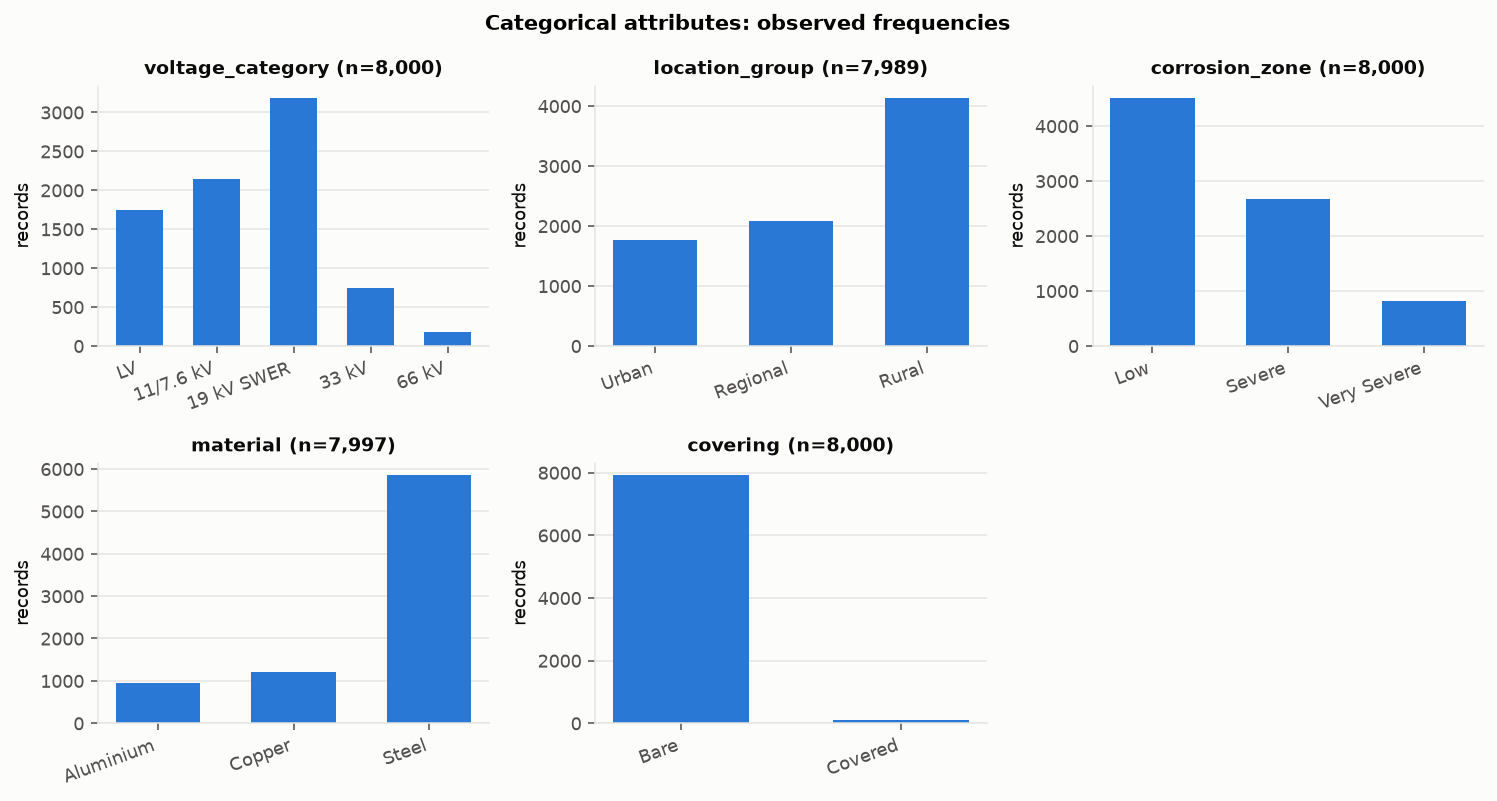

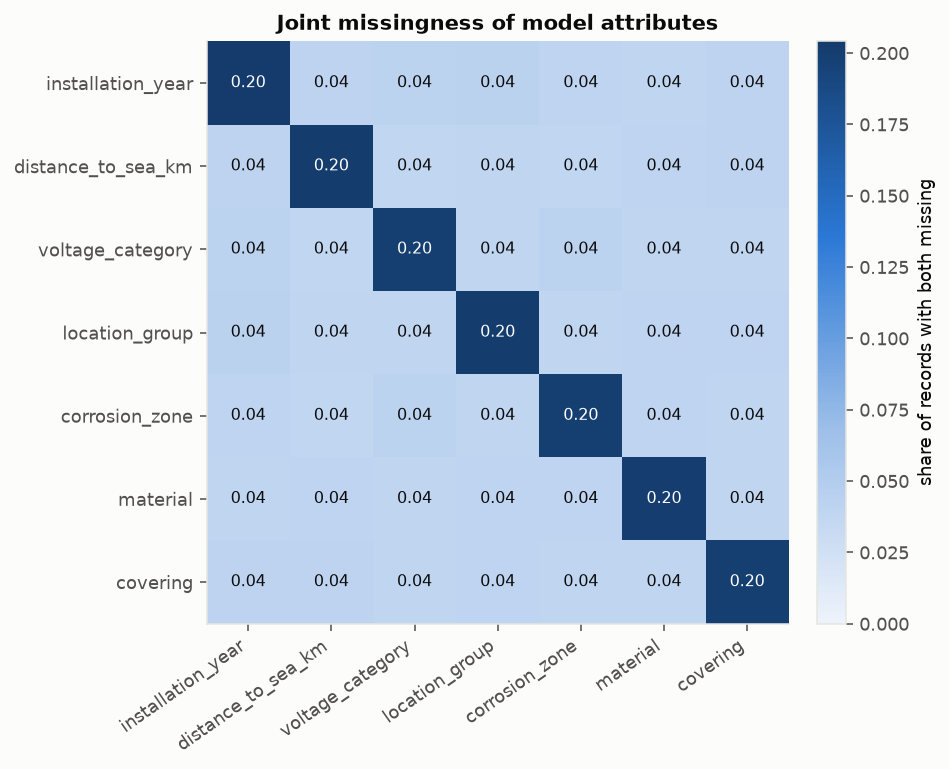

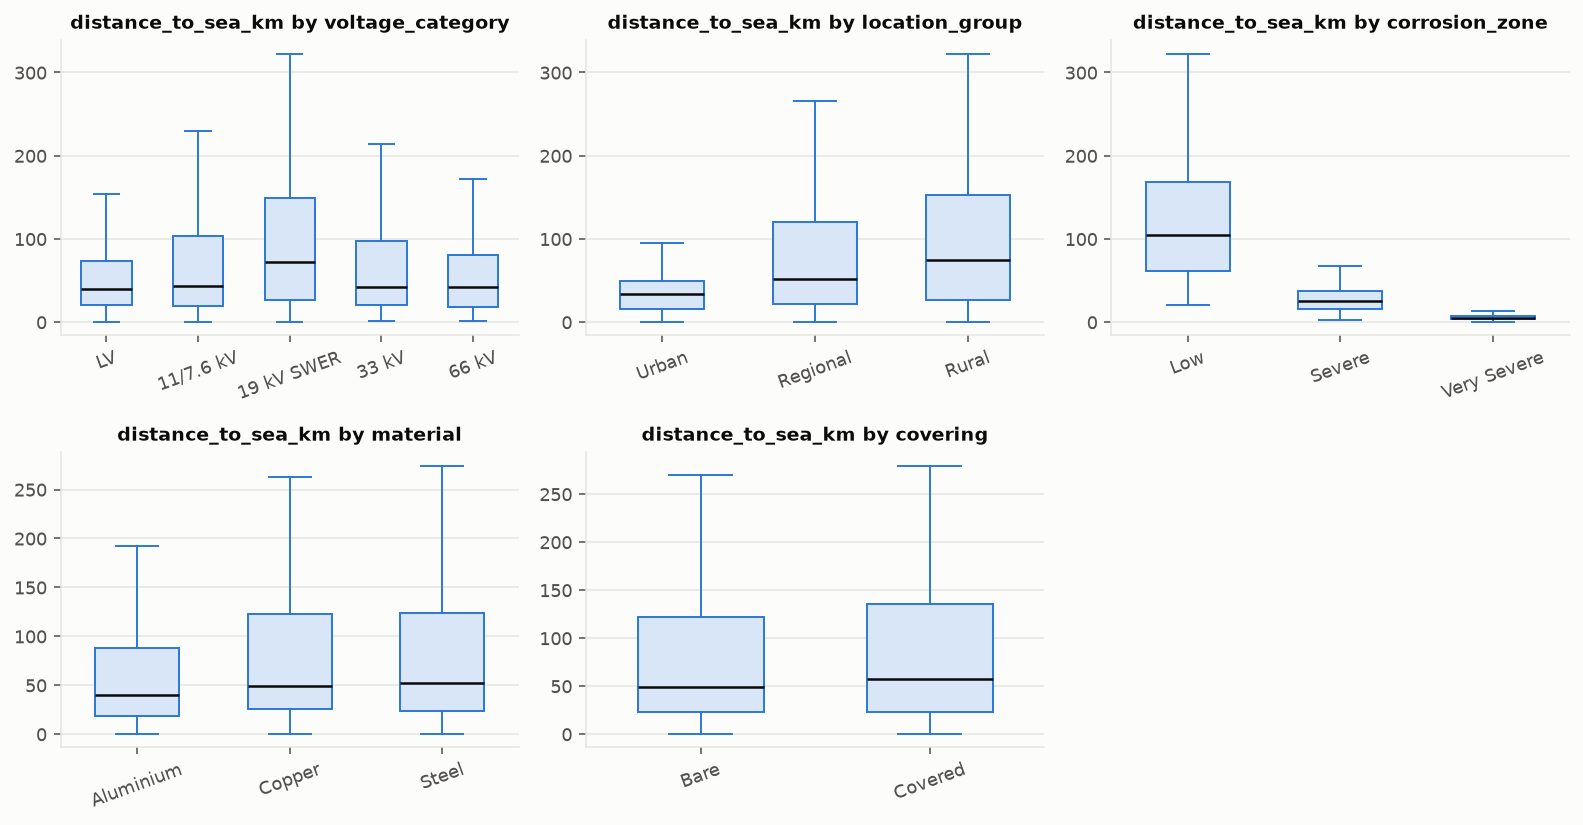

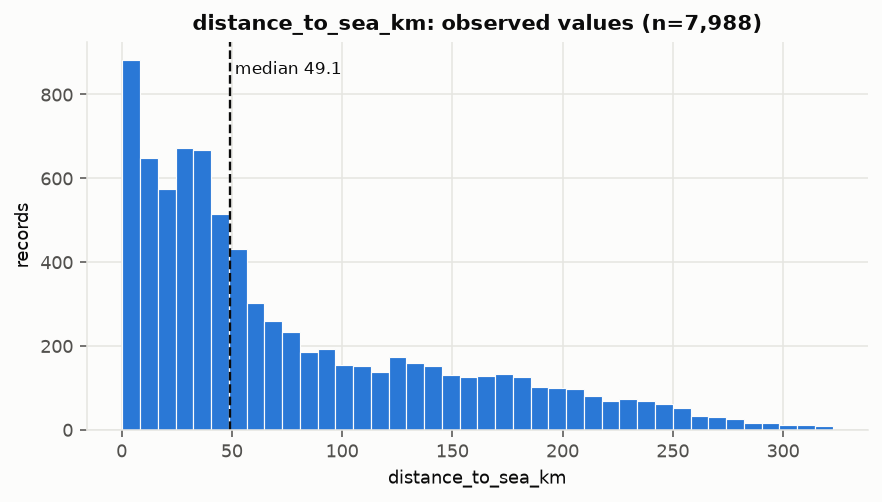

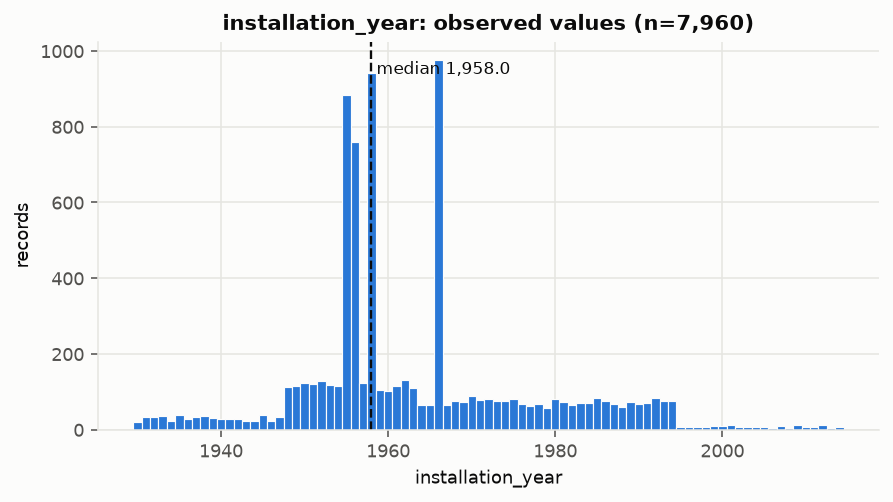

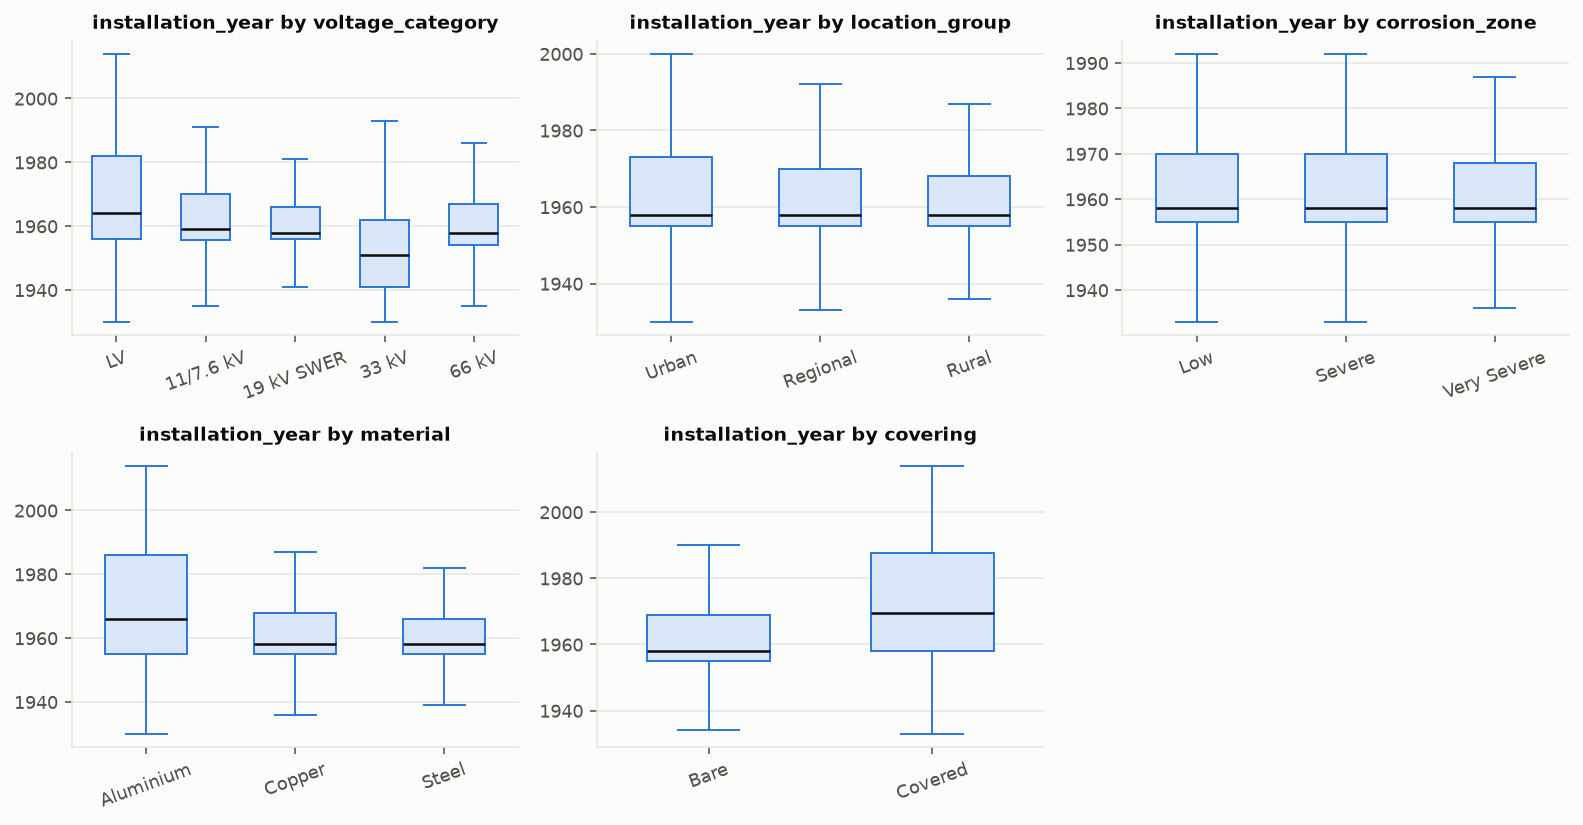

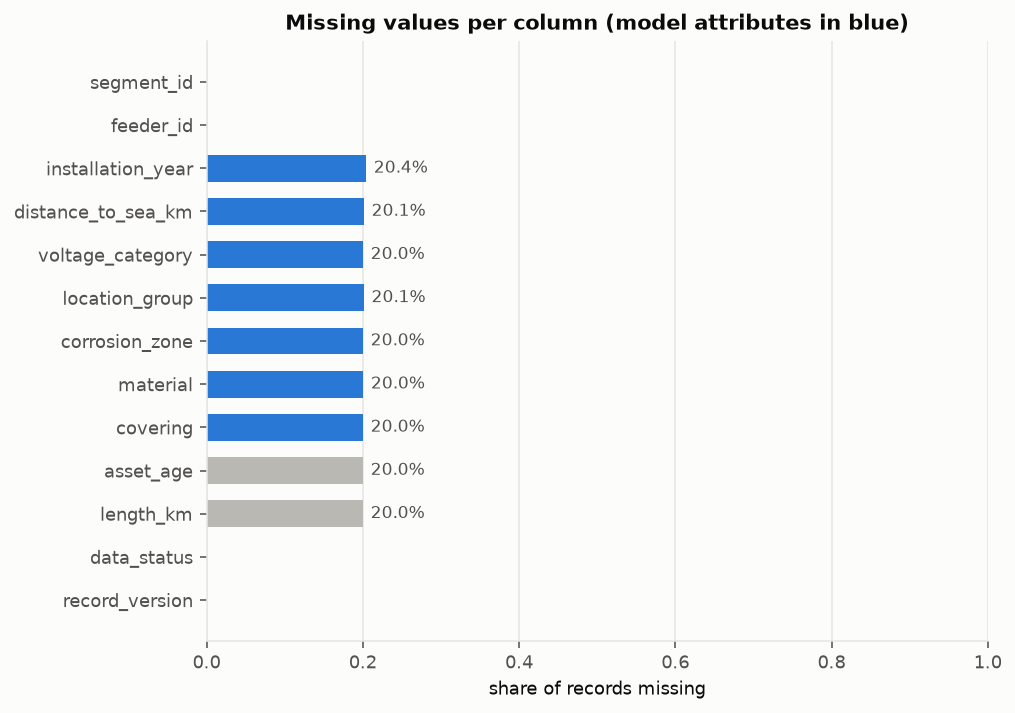

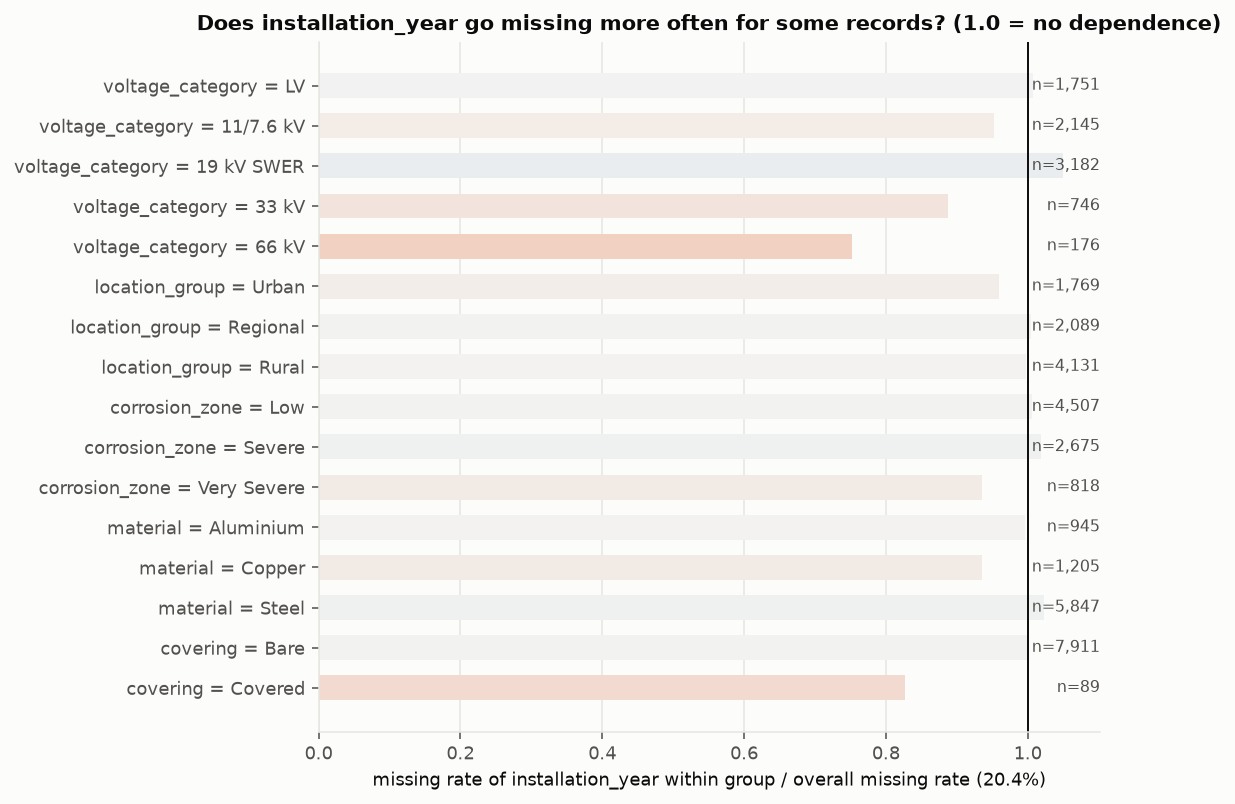

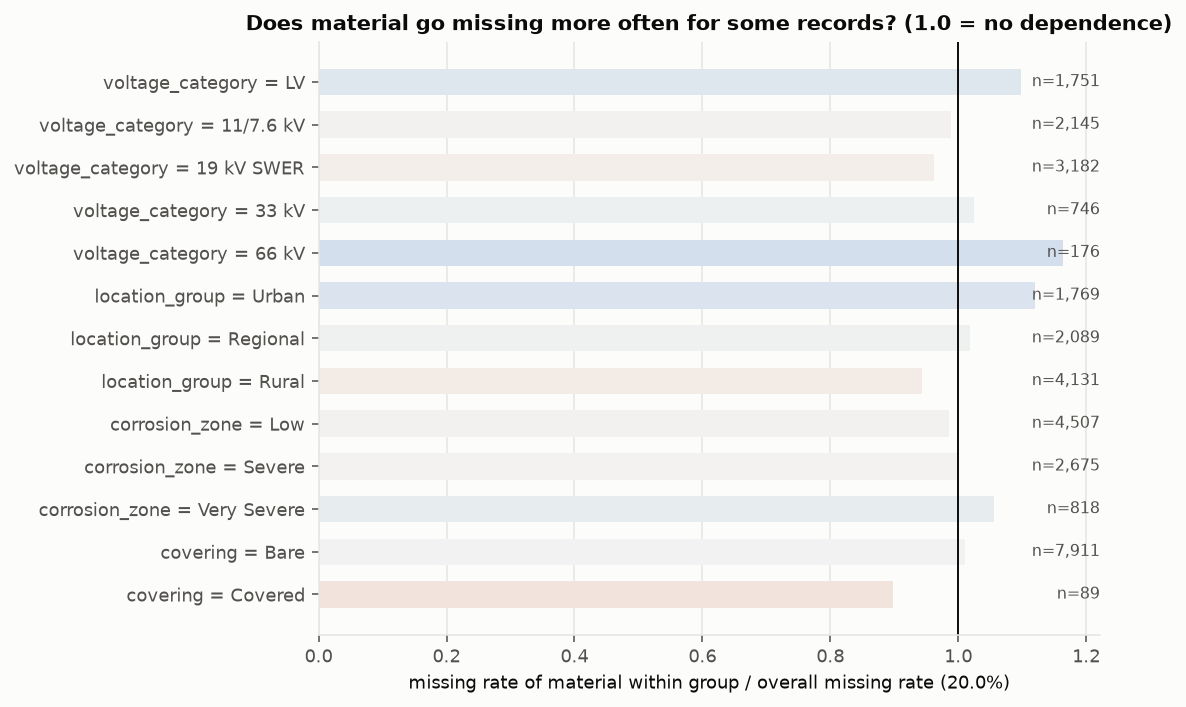

In [13]:
from src.ingestion import apply_schema_types
from src.pipeline import run_clean, run_profile

cleaned = run_clean(INPUT_CSV, run, settings, frame=aligned_frame)
typed = apply_schema_types(cleaned, schema)
cleaning_meta = read_metadata(run)["cleaning"]
print("Cleaned records:", display_path(run.cleaned, PROJECT_ROOT), "| log:", display_path(run.cleaning_log, PROJECT_ROOT))
print({k: cleaning_meta[k] for k in ("rows_in", "rows_out", "cells_changed", "rows_dropped")})

profile_result = run_profile(run.cleaned, run, settings, frame=typed)
display(profile_result.tables["missingness"])
display(table(profile_result.tables["missing_patterns"], 10))
show_images(sorted(run.profile_dir.glob("*.png")))

In [14]:
from src.preprocessing import prepare_for_imputation

prepared = prepare_for_imputation(typed, schema, config)   # run_impute repeats this step internally
model_frame = prepared.model_frame
print("Model attributes (fill and predict):", list(model_frame.model_columns))
print("Primary targets:", list(schema.primary_targets))
print("Carried through, never used for prediction:", list(model_frame.passthrough_columns))
print("Forbidden predictors (schema):", list(schema.forbidden_predictors))
display(prepared.recovery.log)
display(missingness_before_after(typed, prepared.frame, model_frame.model_columns))

Model attributes (fill and predict): ['installation_year', 'distance_to_sea_km', 'voltage_category', 'location_group', 'corrosion_zone', 'material', 'covering']
Primary targets: ['installation_year', 'material']
Carried through, never used for prediction: ['feeder_id', 'asset_age', 'length_km', 'data_status', 'record_version']
Forbidden predictors (schema): ['segment_id', 'feeder_id', 'asset_age', 'conductor_type', 'length_km', 'data_status', 'record_version']


,column,from,snapshot_year,n_recovered,n_rejected_out_of_range,n_still_missing,note
0,installation_year,asset_age,2014,40,0,2000,installation_year = 2014 - asset_age where installation_year was missing and asset_age...


,column,missing_before,missing_after,filled
0,installation_year,2040,2000,40
1,distance_to_sea_km,2012,2012,0
2,voltage_category,2000,2000,0
3,location_group,2011,2011,0
4,corrosion_zone,2000,2000,0
5,material,2003,2003,0
6,covering,2000,2000,0


## 5. Choose imputation method

The registry offers interchangeable methods behind one interface (`fit` / `transform` / `fit_transform` returning imputed values, per-cell diagnostics and metadata): `median_mode` (reference), `missforest` (original transductive MissForest) and `predictive_missforest` (fit/transform adaptation with frozen sequential replay). `METHOD` defaults to `imputation.method` in `pipeline.yaml`; hyperparameters come from `imputation.yaml` (`methods.<name>` plus `selected_hyperparameters`, written by the tuning experiment) and are recorded in `run_metadata.json`.

`run_impute` fits the method on the prepared records and fills their gaps, runs the reference method on the same records, saves a persistable model with provenance, then hands the result to postprocessing (section 6).

In [15]:
from src.imputation import available_methods, resolve_hyperparameters

METHOD = settings.method            # or any of available_methods()
print("Registered methods:", available_methods())
print("Selected:", METHOD, "| reference:", settings.reference_method)
display(key_values(resolve_hyperparameters(config, METHOD, OVERRIDES or None)))

Registered methods: ('median_mode', 'missforest', 'predictive_missforest')
Selected: predictive_missforest | reference: median_mode


,setting,value
0,n_estimators,100
1,n_passes,5
2,random_state,219
3,n_jobs,1
4,max_features,sqrt
5,max_depth,8
6,min_samples_leaf,10
7,class_weight,None
8,numeric_init,mean
9,unknown_category_policy,ignore


In [16]:
from src.pipeline import run_impute

output = run_impute(run.cleaned, run, settings, method=METHOD, overrides=OVERRIDES or None, frame=typed)
imputation_meta = read_metadata(run)["imputation"]

print("Cells imputed:", imputation_meta["cells_imputed"], imputation_meta["cells_imputed_by_column"])
print("Model saved:", display_path(imputation_meta["model_path"], PROJECT_ROOT) if imputation_meta["model_path"] else "no (transductive method)")
print("Method metadata:", {k: v for k, v in imputation_meta["method_metadata"].items() if not isinstance(v, (dict, list))})
display(table(output.diagnostics, 10))
if run.convergence.is_file():
    display(pd.read_csv(run.convergence))

2026-11-06 01:16:48 WARNING configuration: development run on unapproved configuration (pipeline.yaml=changed)
2026-11-06 01:16:48 INFO preparation: recovered {'installation_year': 40}
2026-11-06 01:16:48 INFO imputation: method=predictive_missforest hyperparameters={'n_estimators': 100, 'n_passes': 5, 'random_state': 219, 'n_jobs': 1, 'max_features': 'sqrt', 'max_depth': 8, 'min_samples_leaf': 10, 'class_weight': None, 'numeric_init': 'mean', 'unknown_category_policy': 'ignore', 'min_observed_target': 2} on 10000 rows
2026-11-06 01:16:54 INFO imputation: predictive_missforest filled 14026 cells (6.4s)
2026-11-06 01:16:54 INFO postprocessing: {'observed': 111934, 'derived': 2040, 'imputed': 14026, 'unresolved': 2000}; integrity passed


Cells imputed: 14026 {'corrosion_zone': 2000, 'covering': 2000, 'distance_to_sea_km': 2012, 'installation_year': 2000, 'location_group': 2011, 'material': 2003, 'voltage_category': 2000}
Model saved: pipeline/outputs/overhead_conductors/run_01/model.joblib
Method metadata: {'method': 'predictive_missforest', 'supports_persistence': True, 'transductive': False, 'runtime_seconds': 0.6318261669948697}


,row,column,kind,imputed,prediction_source,raw_prediction,max_proba,margin,entropy,tree_std,tree_p10,tree_p90,material_probabilities
0,4,installation_year,numeric,1962.0,random_forest,1962.355394,NaN,NaN,NaN,1.930478,1960.338818,1963.856646,NaN
1,15,installation_year,numeric,1968.0,random_forest,1968.286711,NaN,NaN,NaN,5.198830,1962.435414,1974.865000,NaN
2,29,installation_year,numeric,1966.0,random_forest,1965.944017,NaN,NaN,NaN,4.206987,1961.576314,1971.443756,NaN
3,33,installation_year,numeric,1967.0,random_forest,1966.686329,NaN,NaN,NaN,3.618988,1962.190853,1970.970770,NaN
4,40,installation_year,numeric,1962.0,random_forest,1962.136829,NaN,NaN,NaN,0.923284,1960.792390,1963.126251,NaN
5,43,installation_year,numeric,1963.0,random_forest,1963.090528,NaN,NaN,NaN,0.694461,1962.451964,1963.846502,NaN
6,45,installation_year,numeric,1962.0,random_forest,1962.443152,NaN,NaN,NaN,1.593355,1960.568201,1964.462244,NaN
7,51,installation_year,numeric,1963.0,random_forest,1963.228963,NaN,NaN,NaN,1.168858,1962.484854,1963.936197,NaN
8,55,installation_year,numeric,1967.0,random_forest,1967.484373,NaN,NaN,NaN,4.393887,1962.960562,1974.448214,NaN
9,57,installation_year,numeric,1963.0,random_forest,1963.008526,NaN,NaN,NaN,0.631075,1962.436617,1963.723790,NaN


,pass,numeric_change,categorical_change,runtime_seconds
0,1,0.000703,0.207310,1.147774
1,2,0.000003,0.032854,1.141845
2,3,0.000002,0.011784,1.150487
3,4,0.000001,0.011384,1.156754
4,5,0.000002,0.013182,1.154139


### Reusing a saved model

A saved `predictive_missforest` model carries a provenance sidecar (fitting rows, identifiers, column roles, constraints, hash). Before `oc-pipeline apply` uses it on new records, `check_compatibility` compares it with the current configuration and input: different model columns are an error; different constraints or unseen category labels are warnings.

In [17]:
from src.imputation import check_compatibility, load_imputer, read_provenance

if run.model.is_file():
    saved = load_imputer(run.model)
    provenance = read_provenance(run.model)
    compatibility = check_compatibility(
        run.model, saved,
        numeric_columns=model_frame.numeric_columns, categorical_columns=model_frame.categorical_columns,
        constraints=config.constraints, frame=prepared.frame,
    )
    print("Fitted on", provenance.get("n_fitting_rows"), "rows at", provenance.get("created_utc"))
    print("Compatibility errors:", compatibility["errors"] or "none")
    print("Compatibility warnings:", compatibility["warnings"] or "none")
else:
    print("No persisted model for this method (transductive); use `impute` on each new table.")

Fitted on 10000 rows at 2026-11-05T14:46:55+00:00
Compatibility errors: none
Compatibility warnings: none


## 6. Postprocessing and cell provenance

After imputation the derived column is filled or recomputed from its (possibly imputed) source, integer columns are exported as integers, and every cell of `final_imputed.csv` is classified: **observed** (left exactly as cleaned), **derived** (deterministic rule), **imputed** (the method) or **unresolved** (still missing). The integrity checks confirm that no observed value changed and that constraints hold; a failure raises before any file is reported as final.

In [18]:
from src.ingestion import load_records

final = apply_schema_types(load_records(run.imputed, schema).frame, schema)
provenance_summary = pd.read_csv(run.provenance_summary)
cells = pd.read_csv(run.cell_provenance)

print("Provenance totals:", imputation_meta["provenance"]["totals"])
print("Unresolved columns:", imputation_meta["provenance"]["unresolved_columns"] or "none")
print("Integrity checks passed:", imputation_meta["integrity_passed"])
display(provenance_summary)
display(missingness_before_after(typed, final, final.columns))

Provenance totals: {'observed': 111934, 'derived': 2040, 'imputed': 14026, 'unresolved': 2000, 'n_cells': 130000}
Unresolved columns: {'length_km': {'n_cells': 2000, 'reason': 'not a model attribute'}}
Integrity checks passed: True


,column,observed,derived,imputed,unresolved,n_cells
0,segment_id,10000,0,0,0,10000
1,feeder_id,10000,0,0,0,10000
2,installation_year,7960,40,2000,0,10000
3,distance_to_sea_km,7988,0,2012,0,10000
4,voltage_category,8000,0,2000,0,10000
5,location_group,7989,0,2011,0,10000
6,corrosion_zone,8000,0,2000,0,10000
7,material,7997,0,2003,0,10000
8,covering,8000,0,2000,0,10000
9,asset_age,8000,2000,0,0,10000


,column,missing_before,missing_after,filled
0,segment_id,0,0,0
1,feeder_id,0,0,0
2,installation_year,2040,0,2040
3,distance_to_sea_km,2012,0,2012
4,voltage_category,2000,0,2000
5,location_group,2011,0,2011
6,corrosion_zone,2000,0,2000
7,material,2003,0,2003
8,covering,2000,0,2000
9,asset_age,2000,0,2000


In [19]:
display(table(cells[cells["status"] == "imputed"], 10))
display(table(cells[cells["status"] == "derived"], 10))
display(pd.read_csv(run.derived_log))
display(final.head(10))

,record_id,column,status,method,value,detail
0,SEG_001904,installation_year,imputed,predictive_missforest,1962,prediction_source=random_forest; tree_std=1.930
1,SEG_006583,installation_year,imputed,predictive_missforest,1968,prediction_source=random_forest; tree_std=5.199
2,SEG_007199,installation_year,imputed,predictive_missforest,1966,prediction_source=random_forest; tree_std=4.207
3,SEG_005980,installation_year,imputed,predictive_missforest,1967,prediction_source=random_forest; tree_std=3.619
4,SEG_006777,installation_year,imputed,predictive_missforest,1962,prediction_source=random_forest; tree_std=0.923
5,SEG_003799,installation_year,imputed,predictive_missforest,1963,prediction_source=random_forest; tree_std=0.694
6,SEG_002687,installation_year,imputed,predictive_missforest,1962,prediction_source=random_forest; tree_std=1.593
7,SEG_007889,installation_year,imputed,predictive_missforest,1963,prediction_source=random_forest; tree_std=1.169
8,SEG_003657,installation_year,imputed,predictive_missforest,1967,prediction_source=random_forest; tree_std=4.394
9,SEG_009106,installation_year,imputed,predictive_missforest,1963,prediction_source=random_forest; tree_std=0.631


,record_id,column,status,method,value,detail
18,SEG_006274,installation_year,derived,recover_source,1993,installation_year = 2014 - asset_age
36,SEG_003137,installation_year,derived,recover_source,1956,installation_year = 2014 - asset_age
128,SEG_005101,installation_year,derived,recover_source,1960,installation_year = 2014 - asset_age
193,SEG_003105,installation_year,derived,recover_source,1979,installation_year = 2014 - asset_age
265,SEG_008228,installation_year,derived,recover_source,1955,installation_year = 2014 - asset_age
299,SEG_008069,installation_year,derived,recover_source,1952,installation_year = 2014 - asset_age
333,SEG_007966,installation_year,derived,recover_source,1951,installation_year = 2014 - asset_age
353,SEG_005486,installation_year,derived,recover_source,1956,installation_year = 2014 - asset_age
376,SEG_004169,installation_year,derived,recover_source,1958,installation_year = 2014 - asset_age
407,SEG_001491,installation_year,derived,recover_source,1951,installation_year = 2014 - asset_age


,column,source,method,snapshot_year,n_filled,n_recomputed_after_source_imputed,n_inconsistent_existing,n_still_missing,note
0,asset_age,installation_year,snapshot_year_minus,2014,2000,0,0,0,existing values kept unless their source was imputed


,segment_id,feeder_id,installation_year,distance_to_sea_km,voltage_category,location_group,corrosion_zone,material,covering,asset_age,length_km,data_status,record_version
0,SEG_000147,R_FDR_030,1935.0,32.080000,19 kV SWER,Rural,Severe,Steel,Bare,79.0,NaN,Synthetic,Complete reference
1,SEG_002263,R_FDR_010,1955.0,281.140000,11/7.6 kV,Rural,Low,Copper,Bare,59.0,0.3335,Synthetic,Complete reference
2,SEG_001822,U_FDR_025,1966.0,11.220000,19 kV SWER,Urban,Very Severe,Steel,Bare,48.0,0.1246,Synthetic,Complete reference
3,SEG_000249,R_FDR_003,1992.0,278.950000,19 kV SWER,Rural,Low,Steel,Bare,22.0,0.7929,Synthetic,Complete reference
4,SEG_001904,R_FDR_045,1962.0,31.020000,11/7.6 kV,Rural,Severe,Steel,Bare,52.0,6.1902,Synthetic,Complete reference
5,SEG_006358,R_FDR_002,1958.0,25.180000,19 kV SWER,Rural,Severe,Steel,Bare,56.0,0.5729,Synthetic,Complete reference
6,SEG_003825,U_FDR_021,1961.0,62.960000,LV,Urban,Severe,Steel,Bare,53.0,0.5642,Synthetic,Complete reference
7,SEG_008154,R_FDR_002,1978.0,27.171546,11/7.6 kV,Regional,Severe,Steel,Bare,36.0,0.2935,Synthetic,Complete reference
8,SEG_004851,R_FDR_012,1969.0,35.980000,19 kV SWER,Rural,Severe,Steel,Bare,45.0,0.4986,Synthetic,Complete reference
9,SEG_002113,U_FDR_023,1992.0,25.250000,LV,Urban,Low,Steel,Bare,22.0,0.1417,Synthetic,Complete reference


## 7. Evaluation and diagnostics

Two different questions, kept apart:

**Operational checks** (`run_validate`) need no ground truth: integrity, distribution shift between observed and imputed values, low-confidence cells, and the *same-table reconstruction check* (hide 10 % of currently observed cells, refit on the masked table, score the hidden cells). The reconstruction check tells how well *known* values are reconstructed on this table; it says nothing about the originally missing cells, which have no truth.

**Evaluation mode** (`run_evaluate`) needs a complete reference. Records are divided into fit / validation / test with the asset's configured partition policy, the measured file's originally missing cells are scored where the truth is known, and only the **test** partition is scored. `unseen_records` fits on the fit partition and transforms the test partition (the operational situation for a persistable method); `transductive` runs `fit_transform` on fit + test together. The validation partition is reserved for tuning and is never scored here. On synthetic data these figures describe the generator, not SAPN's population.

2026-11-06 01:16:56 WARNING configuration: development run on unapproved configuration (pipeline.yaml=changed)
2026-11-06 01:16:56 INFO validation: integrity passed (0 failed checks)
2026-11-06 01:17:03 INFO validation: reconstruction repeat 0 method predictive_missforest (6.5s)
2026-11-06 01:17:03 INFO validation: reconstruction repeat 0 method median_mode (0.1s)


Integrity passed: True | failed checks: 0


,check,column,status,count,detail
0,row_count_unchanged,NaN,pass,0,"10000 in, 10000 out"
1,columns_unchanged,NaN,pass,0,NaN
2,identifier_order_unchanged,segment_id,pass,0,NaN
3,no_missing_after_imputation,installation_year,pass,0,NaN
4,no_missing_after_imputation,distance_to_sea_km,pass,0,NaN
5,no_missing_after_imputation,voltage_category,pass,0,NaN
6,no_missing_after_imputation,location_group,pass,0,NaN
7,no_missing_after_imputation,corrosion_zone,pass,0,NaN
8,no_missing_after_imputation,material,pass,0,NaN
9,no_missing_after_imputation,covering,pass,0,NaN


,variable,variable_type,n_observed,n_imputed,observed_mean,imputed_mean,observed_std,imputed_std,std_ratio,wasserstein_1,ks_statistic,ks_pvalue,total_variation,majority_share_observed,majority_share_imputed,completed_vs_observed_w1,completed_vs_observed_tv
0,installation_year,numeric,8000,2000,1963.428250,1963.596500,14.346274,4.169458,0.290630,8.65425,0.474500,7.351697e-321,NaN,NaN,NaN,1.730850,NaN
1,distance_to_sea_km,numeric,7988,2012,76.863733,82.724661,71.089730,52.611476,0.740071,27.70968,0.230377,2.457805e-75,NaN,NaN,NaN,5.575188,NaN
2,voltage_category,categorical,8000,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.231250,0.397750,0.629000,NaN,0.046250
3,location_group,categorical,7989,2011,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.162178,0.517086,0.679264,NaN,0.032614
4,corrosion_zone,categorical,8000,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.060625,0.563375,0.624000,NaN,0.012125
5,material,categorical,7997,2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.244887,0.731149,0.976036,NaN,0.049051
6,covering,categorical,8000,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.011125,0.988875,1.000000,NaN,0.002225


,method,variable,variable_type,n_masked,mae,rmse,median_absolute_error,nrmse,signed_bias,accuracy,balanced_accuracy,macro_f1,mae_std,macro_f1_std,n_repeats
0,predictive_missforest,installation_year,numeric,800,10.362500,13.414638,8.000000,0.940073,0.480000,NaN,NaN,NaN,NaN,NaN,1
1,predictive_missforest,distance_to_sea_km,numeric,799,43.017265,59.695080,26.341263,0.829790,7.818259,NaN,NaN,NaN,NaN,NaN,1
2,predictive_missforest,voltage_category,categorical,800,NaN,NaN,NaN,NaN,NaN,0.516250,0.347911,0.350990,NaN,NaN,1
3,predictive_missforest,location_group,categorical,799,NaN,NaN,NaN,NaN,NaN,0.574468,0.498824,0.494439,NaN,NaN,1
4,predictive_missforest,corrosion_zone,categorical,801,NaN,NaN,NaN,NaN,NaN,0.744070,0.647935,0.679797,NaN,NaN,1
5,predictive_missforest,material,categorical,799,NaN,NaN,NaN,NaN,NaN,0.717146,0.346561,0.318118,NaN,NaN,1
6,predictive_missforest,covering,categorical,800,NaN,NaN,NaN,NaN,NaN,0.988750,0.500000,0.497172,NaN,NaN,1
7,median_mode,installation_year,numeric,800,10.262500,15.238848,7.000000,1.067910,-5.347500,NaN,NaN,NaN,NaN,NaN,1
8,median_mode,distance_to_sea_km,numeric,799,54.566045,77.461099,36.010000,1.076746,-28.720438,NaN,NaN,NaN,NaN,NaN,1
9,median_mode,voltage_category,categorical,800,NaN,NaN,NaN,NaN,NaN,0.397500,0.200000,0.113775,NaN,NaN,1


Low-confidence cells listed: {'n_cells': 14026, 'n_scored': 14026, 'n_listed': 1428, 'fraction': 0.1, 'listed_by_column': {'corrosion_zone': 200, 'covering': 201, 'distance_to_sea_km': 218, 'installation_year': 204, 'location_group': 202, 'material': 202, 'voltage_category': 201}, 'fallback_cells': 0}


,row,segment_id,column,kind,imputed,prediction_source,raw_prediction,max_proba,margin,entropy,tree_std,tree_p10,tree_p90,material_probabilities,confidence_signal,confidence_rank
0,1688,SEG_009538,corrosion_zone,categorical,Severe,random_forest,Severe,0.416044,0.000253,1.029548,NaN,NaN,NaN,NaN,0.000253,0.00050
1,5879,SEG_009227,corrosion_zone,categorical,Severe,random_forest,Severe,0.470698,0.000318,0.876294,NaN,NaN,NaN,NaN,0.000318,0.00100
2,6381,SEG_001157,corrosion_zone,categorical,Very Severe,random_forest,Very Severe,0.416417,0.000606,1.029191,NaN,NaN,NaN,NaN,0.000606,0.00150
3,3762,SEG_000812,corrosion_zone,categorical,Very Severe,random_forest,Very Severe,0.416521,0.000814,1.029191,NaN,NaN,NaN,NaN,0.000814,0.00200
4,6758,SEG_001517,corrosion_zone,categorical,Severe,random_forest,Severe,0.458682,0.001498,0.923581,NaN,NaN,NaN,NaN,0.001498,0.00250
5,7544,SEG_000319,corrosion_zone,categorical,Very Severe,random_forest,Very Severe,0.413412,0.001797,1.035548,NaN,NaN,NaN,NaN,0.001797,0.00300
6,9942,SEG_004977,corrosion_zone,categorical,Severe,random_forest,Severe,0.412694,0.002557,1.037412,NaN,NaN,NaN,NaN,0.002557,0.00350
7,9173,SEG_002745,corrosion_zone,categorical,Severe,random_forest,Severe,0.413943,0.002983,1.035650,NaN,NaN,NaN,NaN,0.002983,0.00425
8,9305,SEG_004884,corrosion_zone,categorical,Severe,random_forest,Severe,0.413943,0.002983,1.035650,NaN,NaN,NaN,NaN,0.002983,0.00425
9,7624,SEG_006116,corrosion_zone,categorical,Very Severe,random_forest,Very Severe,0.414037,0.003047,1.035544,NaN,NaN,NaN,NaN,0.003047,0.00500


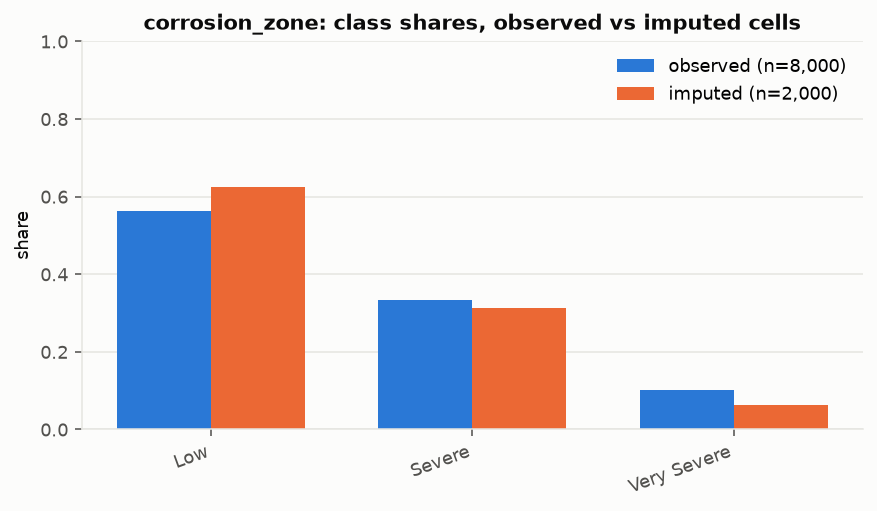

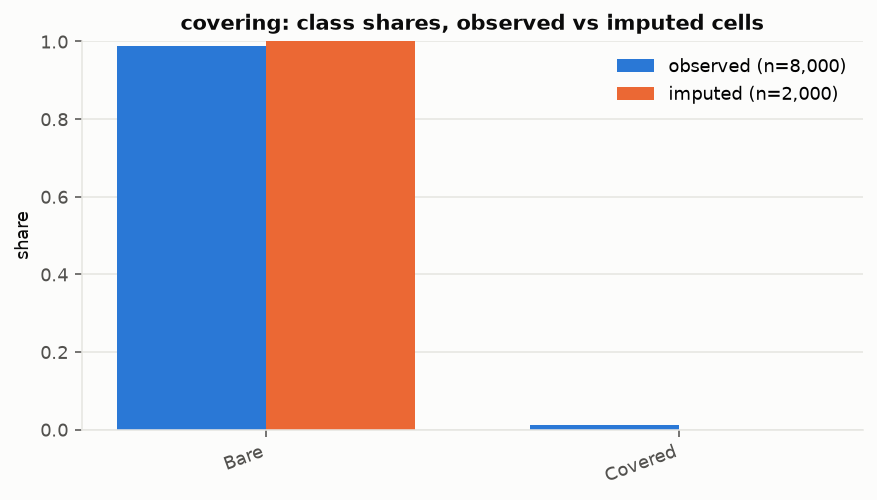

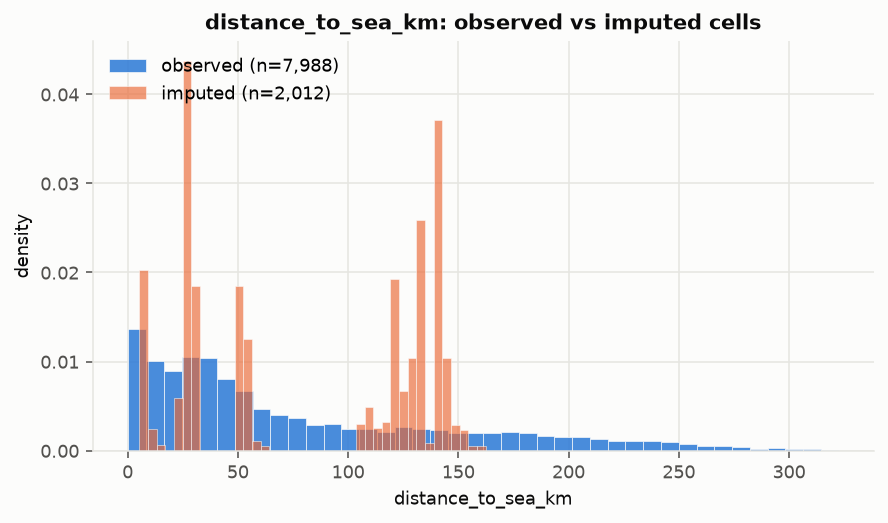

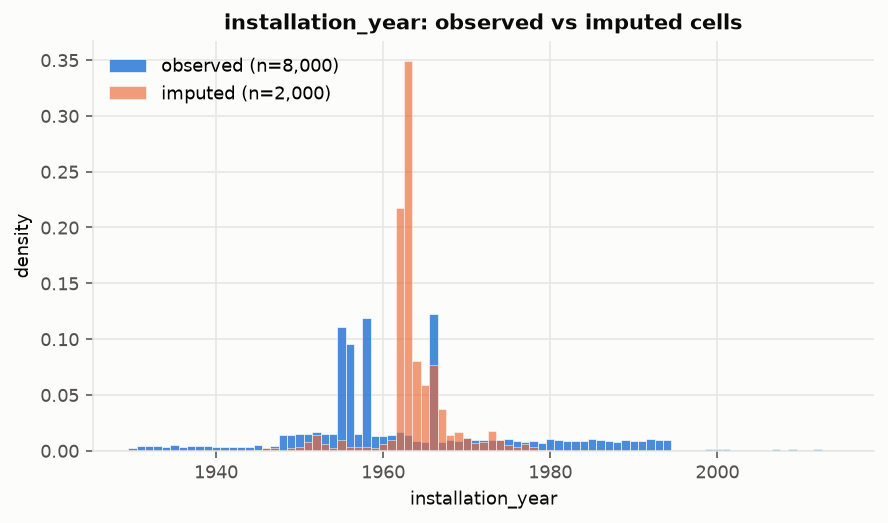

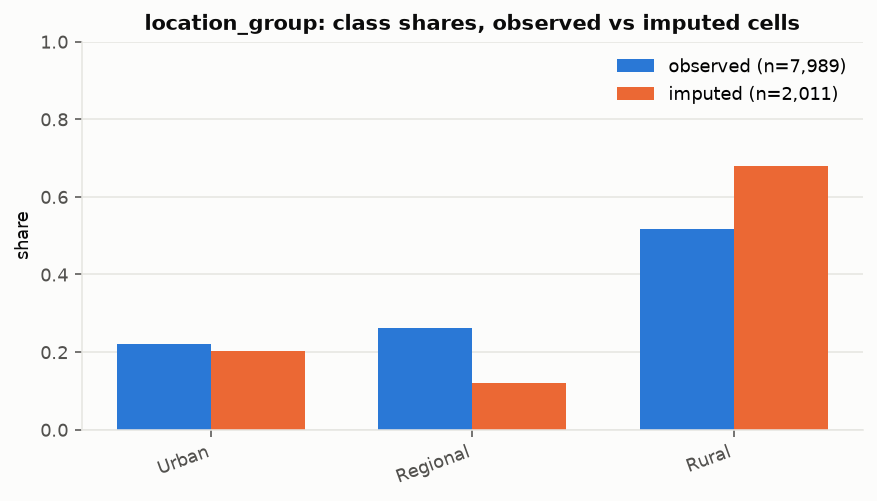

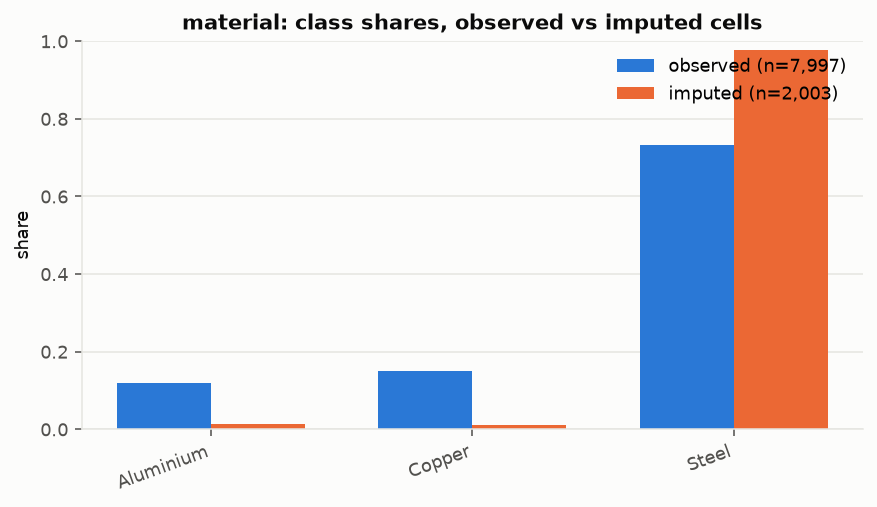

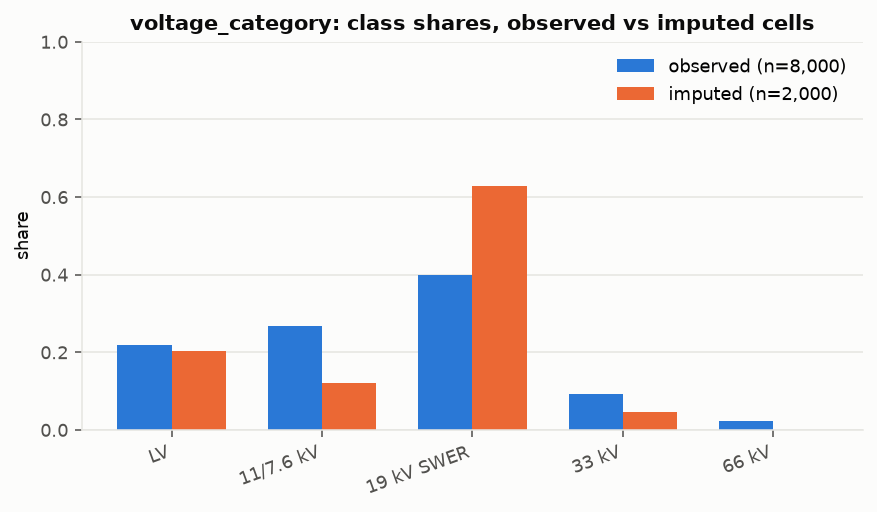

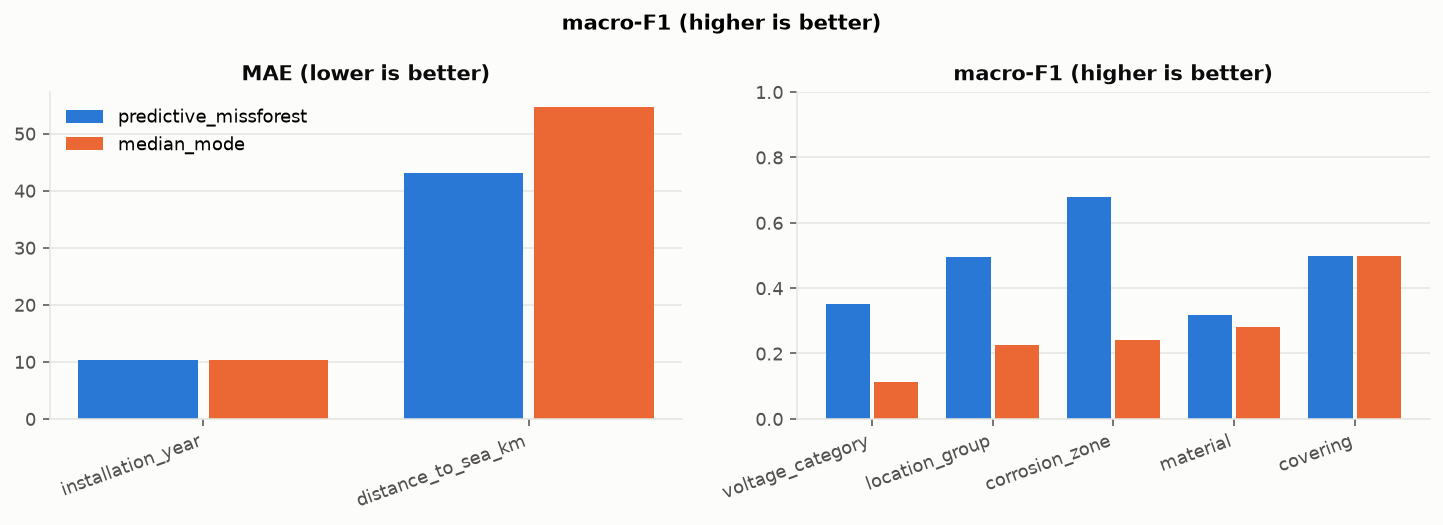

In [20]:
from src.pipeline import run_validate

validation = run_validate(run, settings)
vdir = run.validation_dir
print("Integrity passed:", validation["integrity_passed"], "| failed checks:", validation["integrity_failed_checks"])
display(pd.read_csv(vdir / "integrity_checks.csv"))
display(pd.read_csv(vdir / "distribution_checks.csv"))
if (vdir / "reconstruction_summary.csv").is_file():
    display(pd.read_csv(vdir / "reconstruction_summary.csv"))
if (vdir / "low_confidence_cells.csv").is_file():
    print("Low-confidence cells listed:", validation["confidence"])
    display(table(pd.read_csv(vdir / "low_confidence_cells.csv"), 10))
show_images(sorted((vdir / "figures").glob("*.png")))

2026-11-06 01:17:03 WARNING configuration: development run on unapproved configuration (pipeline.yaml=changed)
2026-11-06 01:17:03 INFO evaluation: mask source masked_input; partitions {'fit': 5976, 'validation': 1542, 'test': 2482}; methods ['predictive_missforest', 'median_mode']
2026-11-06 01:17:08 INFO evaluation: unseen_records predictive_missforest repeat 0 (4.6s)
2026-11-06 01:17:08 INFO evaluation: unseen_records median_mode repeat 0 (0.0s)
2026-11-06 01:17:13 INFO evaluation: transductive predictive_missforest repeat 0 (5.7s)
2026-11-06 01:17:13 INFO evaluation: transductive median_mode repeat 0 (0.0s)
2026-11-06 01:17:14 INFO evaluation complete (10.7s): /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline/outputs/overhead_conductors/run_01/evaluation


Truth: pipeline/data/overhead_conductors/conductors_synthetic_complete.csv | measured input (cleaned): pipeline/outputs/overhead_conductors/run_01/cleaned.csv
Mask source: masked_input | partitions: {'fit': 5976, 'validation': 1542, 'test': 2482} | strategy: group
Methods and hyperparameters: {'predictive_missforest': {'n_estimators': 100, 'n_passes': 5, 'random_state': 219, 'n_jobs': 1, 'max_features': 'sqrt', 'max_depth': 8, 'min_samples_leaf': 10, 'class_weight': None, 'numeric_init': 'mean', 'unknown_category_policy': 'ignore', 'min_observed_target': 2}, 'median_mode': {'numeric_strategy': 'median', 'categorical_strategy': 'mode'}}


,protocol,method,variable,variable_type,n_masked,mae,rmse,median_absolute_error,nrmse,signed_bias,accuracy,balanced_accuracy,macro_f1,fit_seconds,mae_std,macro_f1_std,n_repeats,within_5_years
0,unseen_records,predictive_missforest,installation_year,numeric,498,10.546185,13.797590,8.0,0.968737,-0.373494,NaN,NaN,NaN,4.552509,NaN,NaN,1,0.331325
5,unseen_records,predictive_missforest,material,categorical,518,NaN,NaN,NaN,NaN,NaN,0.685328,0.347297,0.310743,4.552509,NaN,NaN,1,NaN
7,unseen_records,median_mode,installation_year,numeric,498,10.495984,15.345878,8.0,1.077443,-5.712851,NaN,NaN,NaN,0.014386,NaN,NaN,1,0.455823
12,unseen_records,median_mode,material,categorical,518,NaN,NaN,NaN,NaN,NaN,0.693050,0.333333,0.272900,0.014386,NaN,NaN,1,NaN
14,transductive,predictive_missforest,installation_year,numeric,498,10.602410,13.751232,8.0,0.965482,-0.036145,NaN,NaN,NaN,5.708404,NaN,NaN,1,0.305221
19,transductive,predictive_missforest,material,categorical,518,NaN,NaN,NaN,NaN,NaN,0.685328,0.339053,0.294198,5.708404,NaN,NaN,1,NaN
21,transductive,median_mode,installation_year,numeric,498,10.495984,15.345878,8.0,1.077443,-5.712851,NaN,NaN,NaN,0.033917,NaN,NaN,1,0.455823
26,transductive,median_mode,material,categorical,518,NaN,NaN,NaN,NaN,NaN,0.693050,0.333333,0.272900,0.033917,NaN,NaN,1,NaN


,protocol,method,variable,variable_type,n_masked,mae,rmse,median_absolute_error,nrmse,signed_bias,accuracy,balanced_accuracy,macro_f1,fit_seconds,mae_std,macro_f1_std,n_repeats,within_5_years
0,unseen_records,predictive_missforest,installation_year,numeric,498,10.546185,13.797590,8.000000,0.968737,-0.373494,NaN,NaN,NaN,4.552509,NaN,NaN,1,0.331325
1,unseen_records,predictive_missforest,distance_to_sea_km,numeric,525,34.781071,50.725560,19.647970,0.789237,10.534189,NaN,NaN,NaN,4.552509,NaN,NaN,1,NaN
2,unseen_records,predictive_missforest,voltage_category,categorical,506,NaN,NaN,NaN,NaN,NaN,0.515810,0.377933,0.377314,4.552509,NaN,NaN,1,NaN
3,unseen_records,predictive_missforest,location_group,categorical,506,NaN,NaN,NaN,NaN,NaN,0.569170,0.522703,0.514420,4.552509,NaN,NaN,1,NaN
4,unseen_records,predictive_missforest,corrosion_zone,categorical,504,NaN,NaN,NaN,NaN,NaN,0.744048,0.643392,0.670031,4.552509,NaN,NaN,1,NaN
5,unseen_records,predictive_missforest,material,categorical,518,NaN,NaN,NaN,NaN,NaN,0.685328,0.347297,0.310743,4.552509,NaN,NaN,1,NaN
6,unseen_records,predictive_missforest,covering,categorical,512,NaN,NaN,NaN,NaN,NaN,0.986328,0.500000,0.496559,4.552509,NaN,NaN,1,NaN
7,unseen_records,median_mode,installation_year,numeric,498,10.495984,15.345878,8.000000,1.077443,-5.712851,NaN,NaN,NaN,0.014386,NaN,NaN,1,0.455823
8,unseen_records,median_mode,distance_to_sea_km,numeric,525,46.427590,66.435495,31.765000,1.033668,-16.817686,NaN,NaN,NaN,0.014386,NaN,NaN,1,NaN
9,unseen_records,median_mode,voltage_category,categorical,506,NaN,NaN,NaN,NaN,NaN,0.353755,0.200000,0.104526,0.014386,NaN,NaN,1,NaN


,protocol,method,repeat,variable,class,support,predicted,recall,precision,f1
0,unseen_records,predictive_missforest,0,voltage_category,11/7.6 kV,144,86,0.208333,0.348837,0.260870
1,unseen_records,predictive_missforest,0,voltage_category,19 kV SWER,179,253,0.810056,0.573123,0.671296
2,unseen_records,predictive_missforest,0,voltage_category,33 kV,46,19,0.304348,0.736842,0.430769
3,unseen_records,predictive_missforest,0,voltage_category,66 kV,10,0,0.000000,NaN,0.000000
4,unseen_records,predictive_missforest,0,voltage_category,LV,127,148,0.566929,0.486486,0.523636
5,unseen_records,predictive_missforest,0,location_group,Regional,128,83,0.218750,0.337349,0.265403
6,unseen_records,predictive_missforest,0,location_group,Rural,203,309,0.852217,0.559871,0.675781
7,unseen_records,predictive_missforest,0,location_group,Urban,175,114,0.497143,0.763158,0.602076
8,unseen_records,predictive_missforest,0,corrosion_zone,Low,281,289,0.832740,0.809689,0.821053
9,unseen_records,predictive_missforest,0,corrosion_zone,Severe,176,189,0.693182,0.645503,0.668493


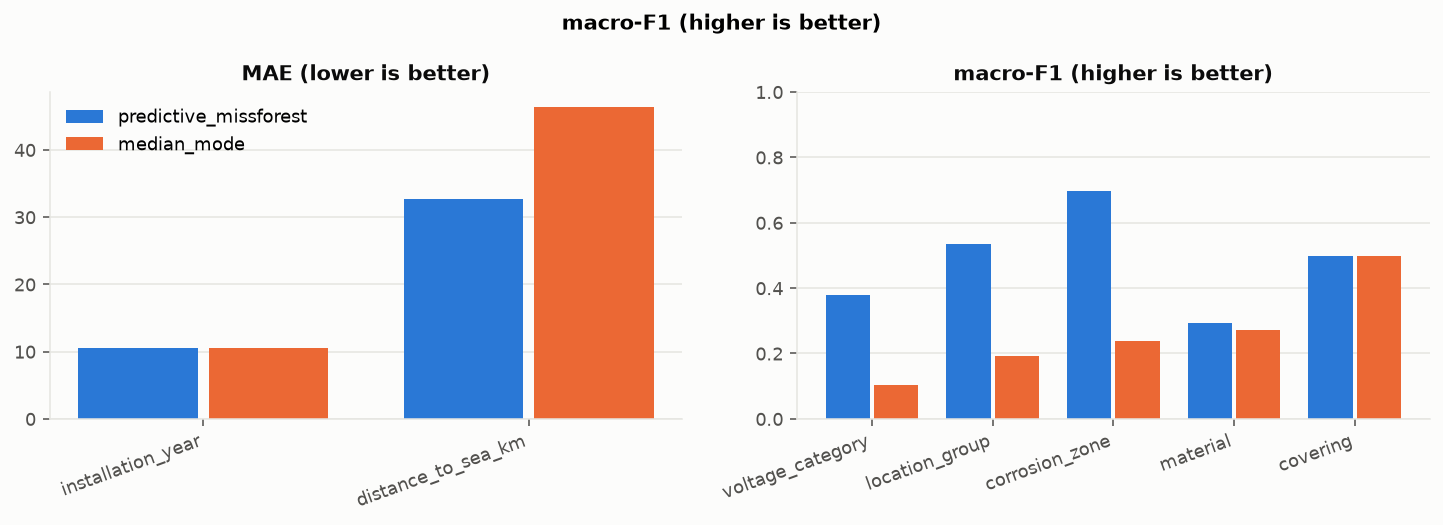

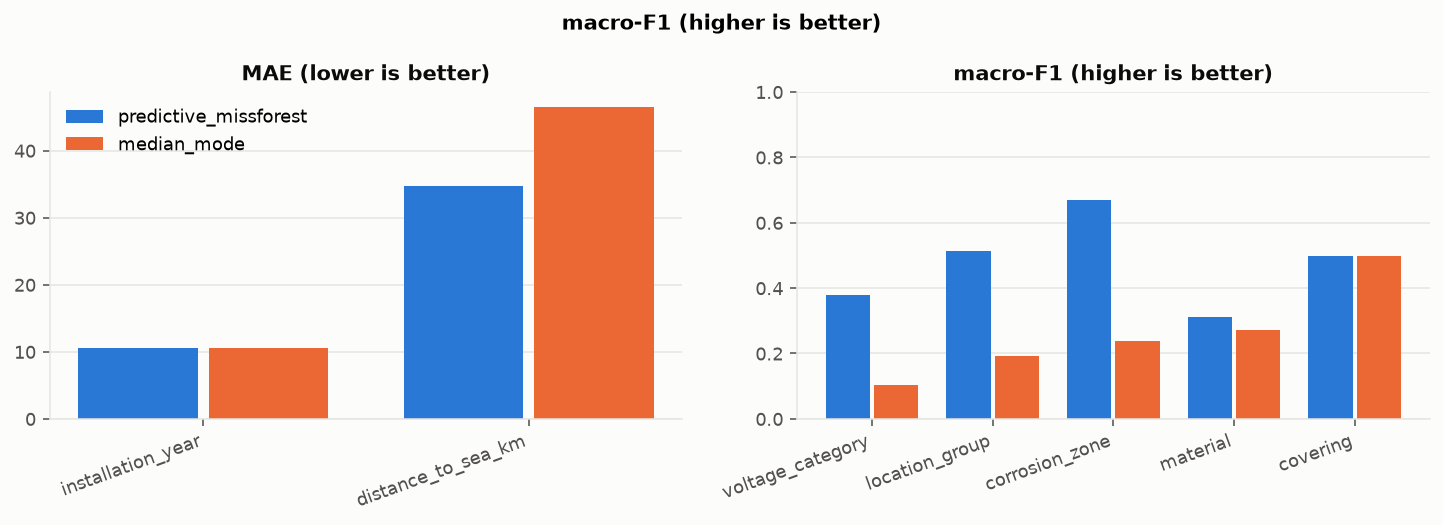

In [21]:
from src.pipeline import run_evaluate

evaluation = run_evaluate(run, settings, truth_csv=TRUTH_CSV, input_csv=run.cleaned, overrides=OVERRIDES or None)
edir = run.evaluation_dir

print("Truth:", display_path(TRUTH_CSV, PROJECT_ROOT), "| measured input (cleaned):", display_path(run.cleaned, PROJECT_ROOT))
print("Mask source:", evaluation["mask_source"], "| partitions:", evaluation["partitions"], "| strategy:", evaluation["partition_strategy"])
print("Methods and hyperparameters:", evaluation["hyperparameters"])
eval_summary = pd.read_csv(edir / "summary.csv")
display(eval_summary[eval_summary["variable"].isin(schema.primary_targets)])
display(eval_summary)
display(table(pd.read_csv(edir / "per_class.csv"), 20))
show_images(sorted((edir / "figures").glob("*.png")))

## 8. Final export and report

The run directory already holds the deliverables; this section renders the single-file HTML report over all of them and lists what to hand over:

- `final_imputed.csv` - completed records in the source column order, integers as integers;
- `cell_provenance.csv` / `provenance_summary.csv` - what was derived, imputed or left unresolved, and by which rule or method;
- `cleaning_log.csv`, `recovery_log.csv`, `derived_fields_log.csv` - every transformation, one row per cell or rule;
- `run_metadata.json` - configuration state and hashes, settings, hyperparameters, per-stage summaries, versions;
- `validation/` and `evaluation/` - the checks and (synthetic) evaluation tables and figures;
- `model.joblib` + `.provenance.json` - the fitted persistable model, if the method supports it;
- `report.html` - all of the above, readable.

The notebook is a readable controller for reusable Python modules, not the only way to execute the system: `oc-pipeline all --asset overhead_conductors --measured <csv> --truth <csv> --out <dir>` produce the same files.

In [22]:
from src.pipeline import run_report

report_path = run_report(run, settings)
meta = read_metadata(run)
print("Report:", display_path(report_path, PROJECT_ROOT))
print("Run metadata:", display_path(run.metadata, PROJECT_ROOT))
print("Package", meta["package_version"], "| configuration ready:", meta["configuration"]["ready"], "| execution mode:", meta["configuration"]["execution_mode"])
display(list_outputs(RUN_DIR, PROJECT_ROOT))

2026-11-06 01:17:14 INFO report: /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline/outputs/overhead_conductors/run_01/report.html (0.1s)


Report: pipeline/outputs/overhead_conductors/run_01/report.html
Run metadata: pipeline/outputs/overhead_conductors/run_01/run_metadata.json
Package 1.1.0 | configuration ready: False | execution mode: development


,file,size_kb
0,pipeline/outputs/overhead_conductors/run_01/cell_provenance.csv,1962.1
1,pipeline/outputs/overhead_conductors/run_01/cleaned.csv,955.7
2,pipeline/outputs/overhead_conductors/run_01/cleaning_log.csv,24.4
3,pipeline/outputs/overhead_conductors/run_01/convergence.csv,0.4
4,pipeline/outputs/overhead_conductors/run_01/derived_fields_log.csv,0.2
...,...,...
58,pipeline/outputs/overhead_conductors/run_01/validation/low_confidence_cells.csv,253.7
59,pipeline/outputs/overhead_conductors/run_01/validation/reconstruction_mask_repeat0.csv,570.0
60,pipeline/outputs/overhead_conductors/run_01/validation/reconstruction_metrics.csv,2.0
61,pipeline/outputs/overhead_conductors/run_01/validation/reconstruction_per_class.csv,2.5
